# Phase B — Individual Implementation
## Conservative LSTM with JAX

**Format:** individual, at home. Implement, train, evaluate, and reflect.

**Prerequisite:** the plan your group wrote in Phase A (`A1_Phase_A_Group_Exercise.ipynb`).

<a id='0'></a>
## 0. Environment setup

Install dependencies if you don't have them yet.

In [1]:
# Uncomment if needed (e.g. a fresh environment or Colab)
%pip install -q "jax[cpu]" flax optax matplotlib
    
import jax
import jax.numpy as jnp
import flax.linen as nn
import optax
import numpy as np
import matplotlib.pyplot as plt
import time

print("JAX version:", jax.__version__)
print("Devices    :", jax.devices())

Note: you may need to restart the kernel to use updated packages.


JAX version: 0.12.1
Devices    : [CpuDevice(id=0)]


<a id='1'></a>
## 1. Introduction to JAX and Flax

JAX is a numerical computing library built around a **functional** programming style. Its syntax is close to NumPy, with three key additions:

| Function | What it does |
|---|---|
| `jax.grad` | Automatic differentiation (exact gradients of any Python function) |
| `jax.jit` | Just-in-time compilation (XLA) → much faster execution |
| `jax.vmap` | Automatic vectorization over a batch axis |

Random numbers use **explicit keys** (`PRNGKey`) instead of a global seed — the same key always gives the same numbers, which makes your code fully reproducible. Neural networks are built with **Flax** (`flax.linen`, imported as `nn`), a layer on top of JAX for trainable models.

Two things to keep in mind:
- JAX functions should be **pure** (no side effects) so that `jit`/`grad` work correctly.
- JAX arrays are **immutable**: you don't modify them in place, you return new ones.

Run the demo below to see all three capabilities in action.

In [2]:
# Mini-demo of JAX's three key capabilities

# (a) Automatic differentiation
f = lambda x: x ** 3 + 2 * x
df = jax.grad(f)                # derivative: 3x^2 + 2
print("f'(2) =", df(2.0), "(expected 14.0)")

# (b) Explicit random keys -> reproducibility
key = jax.random.PRNGKey(0)
k1, k2 = jax.random.split(key)
print("Reproducible sample:", jax.random.normal(k1, (3,)))

# (c) JIT + vmap
g = jax.jit(jax.vmap(f))        # applies f to a whole vector, compiled
print("g([1,2,3]) =", g(jnp.array([1., 2., 3.])))

f'(2) = 14.0 (expected 14.0)


Reproducible sample: [ 1.0040144  -0.90633726 -0.7481722 ]
g([1,2,3]) = [ 3. 12. 33.]


### Flax basics for recurrent models

- A `nn.Module` describes the *computation*, not the state. You create parameters with `model.init(key, dummy_input)` (returns a `params` pytree), then run the network with `model.apply(params, x)` — `params` is always passed explicitly.
- For recurrence, Flax provides `nn.LSTMCell` (one timestep) and `nn.RNN` (unrolls a cell over a whole sequence). You'll use both below.

### Optax for optimization

```python
optimizer = optax.adam(learning_rate=1e-2)
opt_state = optimizer.init(params)

loss, grads = jax.value_and_grad(loss_fn)(params, batch)
updates, opt_state = optimizer.update(grads, opt_state, params)
params = optax.apply_updates(params, updates)
```

Wrapping this whole step in `@jax.jit` compiles it once and reuses the compiled version on every call — this is what makes JAX training loops fast.

A simple example is often enough to illustrate the Flax programming model before introducing recurrence. The following network learns a basic regression problem using a small multilayer perceptron.

In [3]:
import jax
import jax.numpy as jnp
from flax import linen as nn
import optax


# ---------------------------------------------------------
# 1. Define a simple neural network
# ---------------------------------------------------------

class SimpleMLP(nn.Module):
    hidden_size: int = 32

    # @nn.compact is a decorator in Flax that tells the framework:
    # “The layers used inside this method should be created automatically 
    # the first time the method is called.”
    # It is the most common way to define Flax models.

    @nn.compact
    def __call__(self, x):
        x = nn.Dense(self.hidden_size)(x)
        x = nn.relu(x)
        x = nn.Dense(1)(x)
        return x

# ---------------------------------------------------------
# 2. Create a synthetic regression dataset
# ---------------------------------------------------------

key = jax.random.PRNGKey(0)
key, data_key, init_key = jax.random.split(key, 3)
x_train = jax.random.normal(data_key, shape=(128, 4))
y_train = (
    2.0 * x_train[:, 0]
    - 1.5 * x_train[:, 1]
    + 0.5 * x_train[:, 2]
    + 0.2
)
y_train = y_train[:, None]

# ---------------------------------------------------------
# 3. Create the model and initialize its parameters
# ---------------------------------------------------------

model = SimpleMLP(hidden_size=16)
dummy_input = jnp.ones((1, 4))
params = model.init(init_key, dummy_input)

# ---------------------------------------------------------
# 4. Define the loss function
# ---------------------------------------------------------

def loss_fn(params, x, y):
    predictions = model.apply(params, x)
    loss = jnp.mean((predictions - y) ** 2)
    return loss

# ---------------------------------------------------------
# 5. Create the optimizer
# ---------------------------------------------------------

optimizer = optax.adam(learning_rate=1e-3)
opt_state = optimizer.init(params)

# ---------------------------------------------------------
# 6. Define one training step
# ---------------------------------------------------------

@jax.jit
def train_step(params, opt_state, x, y):
    loss, gradients = jax.value_and_grad(loss_fn)(
        params,
        x,
        y
    )
    updates, opt_state = optimizer.update(
        gradients,
        opt_state,
        params
    )
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

# ---------------------------------------------------------
# 7. Train the model
# ---------------------------------------------------------

num_epochs = 1000

for epoch in range(num_epochs):
    params, opt_state, loss = train_step(
        params,
        opt_state,
        x_train,
        y_train
    )
    if epoch % 100 == 0:
        print(f"Epoch {epoch:4d} | Loss: {float(loss):.6f}")

# ---------------------------------------------------------
# 8. Evaluate the trained model
# ---------------------------------------------------------

predictions = model.apply(params, x_train)
final_loss = jnp.mean(
    (predictions - y_train) ** 2
)
print(f"Final loss: {float(final_loss):.6f}")


# ---------------------------------------------------------
# 9. Test the model with new samples
# ---------------------------------------------------------

x_test = jnp.array([
    [1.0, 2.0, 3.0, 4.0],
    [-1.0, 0.5, 2.0, 1.0]
])
predicted_values = model.apply(params, x_test)
true_values = (
    2.0 * x_test[:, 0]
    - 1.5 * x_test[:, 1]
    + 0.5 * x_test[:, 2]
    + 0.2
)

print("\nPredictions:")
print(predicted_values.squeeze())

print("\nTrue values:")
print(true_values)

Epoch    0 | Loss: 5.076825
Epoch  100 | Loss: 2.333333
Epoch  200 | Loss: 0.558173
Epoch  300 | Loss: 0.102863
Epoch  400 | Loss: 0.051410
Epoch  500 | Loss: 0.036595
Epoch  600 | Loss: 0.029150
Epoch  700 | Loss: 0.024714
Epoch  800 | Loss: 0.022067
Epoch  900 | Loss: 0.019799


Final loss: 0.017727



Predictions:
[ 0.6405684 -1.637457 ]

True values:
[ 0.7  -1.55]


<a id='2'></a>
## 2. Scientific background (recap)

Many physical systems obey **conservation laws** (mass, energy, charge, momentum, ...). A conventional neural network trained only to minimize prediction error has no notion of these laws.

Phase A (§2) asked you to compare four ways of incorporating the conservation law and to choose one for your group's plan. This notebook has you implement **two** models: the **baseline** (§5, Option 1 — direct prediction, no physical structure) and **your model** (§6 — whichever of Options 2/3/4 your group chose), then compare them. This is one instance of **physics-informed machine learning**: known structure shrinks the space of functions the network can represent, so a well-chosen architecture can be both physically valid *and* need less data to generalize well.

<a id='3'></a>
## 3. The scenario (recap)

| Symbol | Meaning | Observed? |
|---|---|---|
| `m(t)` | Water mass (volume) in the reservoir | yes |
| `r(t)` | Inflow | yes |
| `q(t)` | Controlled outflow | yes |
| `c(t)` | Hidden consumption | **no** |

$$ m(t+1) = m(t) + r(t) - q(t) - c(t) $$

As in Phase A §1, `c(t)` depends on temperature, hour of day, day of year, and its own small random noise; it is the only unobserved term in the mass balance.

Models will only ever see `x(t) = [m(t), r(t), q(t), temp(t), hour(t), day_year(t)]` as input (matching the variables Phase A identified as driving `c(t)`). The target for training is `m(t+1)`.

<a id='4'></a>
## 4. Task 5.1 — Generate synthetic sequential data

Simulate `N` independent sequences of length `T` (e.g. `N=400`, `T=480` hourly steps ≈ 20 days).

**Design notes / hints:**
- **Inflow / outflow.** The simplest valid design samples `r(t)` and `q(t)` i.i.d. from a fixed range at every timestep (e.g. `r(t) ~ U[2.0, 3.5]`, `q(t) ~ U[1.0, 2.0]`) — they don't need to be autocorrelated or seasonal, since they're always fully observed anyway.
- **Temperature.** Give it a daily cycle plus per-sequence and per-step noise, e.g.
  `temp(t) = 20 + 8·sin(2π(hour(t) − 6)/24) + offset_seq + noise(t)`, where `offset_seq` is drawn once per sequence and `noise(t)` independently at every step.
- **Day of year.** A sequence spans a small window of days (e.g. `T=480` hours ≈ 20 days), so `day_year(t)` is close to constant within a sequence but differs across sequences — draw one starting day per sequence (e.g. `U[0, 365]`) and increment it as `t` advances. Normalize to `[0, 1]` for the network input, same as `hour_norm`.
- **Hidden consumption `c(t)`.** Build it from a base level, a temperature term, and a daily usage profile, then clip to non-negative:

  ```
  hour_profile(t) = 0.5 · (1 + sin(2π(hour(t) − 8)/24))   # peaks around midday/evening
  c_raw(t)        = c0 + α·(temp(t) − mean(temp)) + β·hour_profile(t) + noise_c(t)
  c(t)            = max(0, c_raw(t))                       # consumption can't be negative
  ```

  (e.g. `c0=1.0`, `α=0.05`, `β=1.2`, small-amplitude `noise_c`). Note it's the **clipping**, not the formula itself, that enforces non-negativity. (You could also make `c0`/`α`/`β` depend on `day_year(t)` — e.g. a seasonal component — but a constant base level is enough to complete the task.)
- Roll the mass forward: pick `m(0)` (e.g. `100 + U[0,10]`), then apply `m(t+1) = m(t) + r(t) - q(t) - c(t)` step by step to build the whole sequence.
- Store `X = [m, r, q, temp, hour_norm, day_year_norm]` (that feature order), `Y = m(t+1)`, and `C` (true hidden consumption, diagnostics only).

### 4.0 Configuration and random keys ★

Every setting of the notebook lives in one dictionary, `CONFIG`, so that the two models and all the experiments read the same values and nothing is hard-coded twice.

JAX has no global random state: every random call takes an explicit **key**, and the same key always gives the same numbers. Two kinds of key are used here:

- `data_key` produces all the data. The main data set and the cold-spell copy (4.3) are both generated from it, so they share every random draw and differ only in the temperature.
- `run_key(name, seed)` gives each training run its own key, built from the base seed and the run's name. `zlib.crc32` turns the name into a stable integer (Python's `hash` changes between sessions), and `jax.random.fold_in` mixes it into the seed. A run's key therefore depends only on its name, never on the order in which cells are executed.

This cell replaces the template's `PRNGKey(42)`: the base seed is 112358. It also creates `results/`, where each training run is cached (section 7).

In [4]:
import os, zlib

CONFIG = {
    "seed": 112358,
    "n_seq": 450, "T": 480,
    "n_train": 300, "n_val": 50, "n_test": 100,
    "hidden_size": 32, "learning_rate": 1e-2, "clip_norm": 1.0,
    "epochs": 300, "batch_size": 32,
    "mu_grid": [0.01, 0.1, 1.0],
    "n_train_grid": [25, 50, 100, 200],
    "temp_shift": -15.0,
    "use_cache": True,
}


def run_key(name, seed=CONFIG["seed"]):
    """PRNG key of one training run.

    name : str, the run's name (e.g. "baseline_s112358")
    seed : int, base seed
    Returns a key that depends only on (seed, name): crc32 is stable across sessions.
    """
    return jax.random.fold_in(jax.random.PRNGKey(seed), zlib.crc32(name.encode()) % 2**31)


# One key for all the data (main set and cold-spell copy share it).
data_key = jax.random.fold_in(jax.random.PRNGKey(CONFIG["seed"]), 0)

os.makedirs("results", exist_ok=True)

for k, v in CONFIG.items():
    print(f"{k:14s}: {v}")

assert CONFIG["n_train"] + CONFIG["n_val"] + CONFIG["n_test"] == CONFIG["n_seq"]
assert os.path.isdir("results")

seed          : 112358
n_seq         : 450
T             : 480
n_train       : 300
n_val         : 50
n_test        : 100
hidden_size   : 32
learning_rate : 0.01
clip_norm     : 1.0
epochs        : 300
batch_size    : 32
mu_grid       : [0.01, 0.1, 1.0]
n_train_grid  : [25, 50, 100, 200]
temp_shift    : -15.0
use_cache     : True


### 4.1 The data generator ★

`generate_data` follows the design notes above, with two changes to the example values: the inflow is `r ~ U[2.35, 3.85]` and the initial volume `m(0) = 150 + U[0, 10]`. With the example values the reservoir loses about 0.35 per hour on average and its volume becomes negative within a sequence; with these it stays positive.

- **One sub-key per random quantity** (`h0`, `d0`, `r`, `q`, the sequence offset, the temperature noise, the consumption noise, `m(0)`), all split from the one key passed in.
- **Consumption:** `c = max(0, 1.0 + 0.05·(temp − 20) + 1.2·hour_profile + noise_c)`, `noise_c ~ N(0, 0.1²)`. The reference temperature is the constant 20 (the mean of the temperature formula), so a colder copy of the data (`temp_shift`) really has lower consumption.
- **Mass:** instead of a Python loop, `m(t+1) = m(0) + cumsum(r − q − c)`; `m(t)` is `m(0)` followed by `m(t+1)` shifted one step. This is the balance applied step by step, written as one array operation.
- **Output:** `X = [m, r, q, temp, hour_norm, day_year_norm]`, `Y = m(t+1)`, and `C`, the true consumption, kept only for diagnostics after training.

The checks confirm the shapes, the ranges, that the balance holds exactly in the generated data, and that the generator is reproducible.

In [5]:
def generate_data(key, n_seq=CONFIG["n_seq"], T=CONFIG["T"], temp_shift=0.0):
    """Generate n_seq sequences of length T for the water-reservoir system.

    key        : PRNG key (split into one sub-key per random quantity)
    temp_shift : constant added to the temperature (°C); 0 for the main data
    Returns
    X : (n_seq, T, 6) float32 -> [m, r, q, temp, hour_norm, day_year_norm]
    Y : (n_seq, T)    float32 -> m(t+1)
    C : (n_seq, T)    float32 -> true hidden consumption (diagnostics only)
    """
    k_h0, k_d0, k_r, k_q, k_off, k_tn, k_c, k_m0 = jax.random.split(key, 8)
    t = jnp.arange(T)

    h0 = jax.random.randint(k_h0, (n_seq, 1), 0, 24)                 # starting hour per sequence
    hour = (h0 + t[None, :]) % 24                                      # (n_seq, T), integers 0..23
    d0 = jax.random.uniform(k_d0, (n_seq, 1), minval=0.0, maxval=365.0)
    day_year = (d0 + t[None, :] / 24.0) % 365.0

    r = jax.random.uniform(k_r, (n_seq, T), minval=2.35, maxval=3.85)  # inflow
    q = jax.random.uniform(k_q, (n_seq, T), minval=1.0, maxval=2.0)    # controlled outflow

    offset_seq = jax.random.normal(k_off, (n_seq, 1))                  # per-sequence offset
    temp = (20.0 + temp_shift + 8.0 * jnp.sin(2 * jnp.pi * (hour - 6) / 24)
            + offset_seq + jax.random.normal(k_tn, (n_seq, T)))

    hour_profile = 0.5 * (1 + jnp.sin(2 * jnp.pi * (hour - 8) / 24))
    noise_c = 0.1 * jax.random.normal(k_c, (n_seq, T))
    # Reference temperature is the constant 20, so a temperature shift changes c.
    c = jnp.maximum(0.0, 1.0 + 0.05 * (temp - 20.0) + 1.2 * hour_profile + noise_c)

    m0 = 150.0 + jax.random.uniform(k_m0, (n_seq, 1), minval=0.0, maxval=10.0)
    m_next = m0 + jnp.cumsum(r - q - c, axis=1)                        # m(t+1), the balance rolled forward
    m = jnp.concatenate([m0, m_next[:, :-1]], axis=1)                  # m(t)

    X = jnp.stack([m, r, q, temp, hour / 24.0, day_year / 365.0], axis=-1).astype(jnp.float32)
    return X, m_next.astype(jnp.float32), c.astype(jnp.float32)


X, Y, C = generate_data(data_key)
print("X:", X.shape, " Y:", Y.shape, " C:", C.shape)
balance_gap = float(jnp.max(jnp.abs(Y - (X[..., 0] + X[..., 1] - X[..., 2] - C))))
print(f"max |Y - (m + r - q - C)| = {balance_gap:.2e}")
print(f"min C = {float(C.min()):.3f},  min m = {float(X[..., 0].min()):.1f}")

assert X.shape == (450, 480, 6) and Y.shape == (450, 480) and C.shape == (450, 480)
assert bool(jnp.all(C >= 0)) and bool(jnp.all(X[..., 0] > 0))
for j in (4, 5):                                   # hour_norm, day_year_norm in [0, 1)
    assert bool(jnp.all((X[..., j] >= 0) & (X[..., j] < 1)))
assert not (bool(jnp.isnan(X).any()) or bool(jnp.isnan(Y).any()) or bool(jnp.isnan(C).any()))
assert balance_gap < 1e-3
assert bool(jnp.allclose(Y[:, :-1], X[:, 1:, 0]))  # m(t+1) of one step is m of the next
Xa, _, _ = generate_data(data_key, n_seq=4, T=24)
Xb, _, _ = generate_data(data_key, n_seq=4, T=24)
Xc, _, _ = generate_data(jax.random.PRNGKey(1), n_seq=4, T=24)
assert bool(jnp.array_equal(Xa, Xb)) and not bool(jnp.array_equal(Xa, Xc))

X: (450, 480, 6)  Y: (450, 480)  C: (450, 480)
max |Y - (m + r - q - C)| = 3.05e-05
min C = 0.151,  min m = 80.3


### 4.2 Sanity-check plot

One training sequence in three panels: the volume, the three flows (the hidden consumption `c` drawn thick, because it is the term the models must infer), and the temperature that drives part of `c`. The daily cycles should be visible in `c` and in the temperature, and the volume should drift slowly without becoming negative.

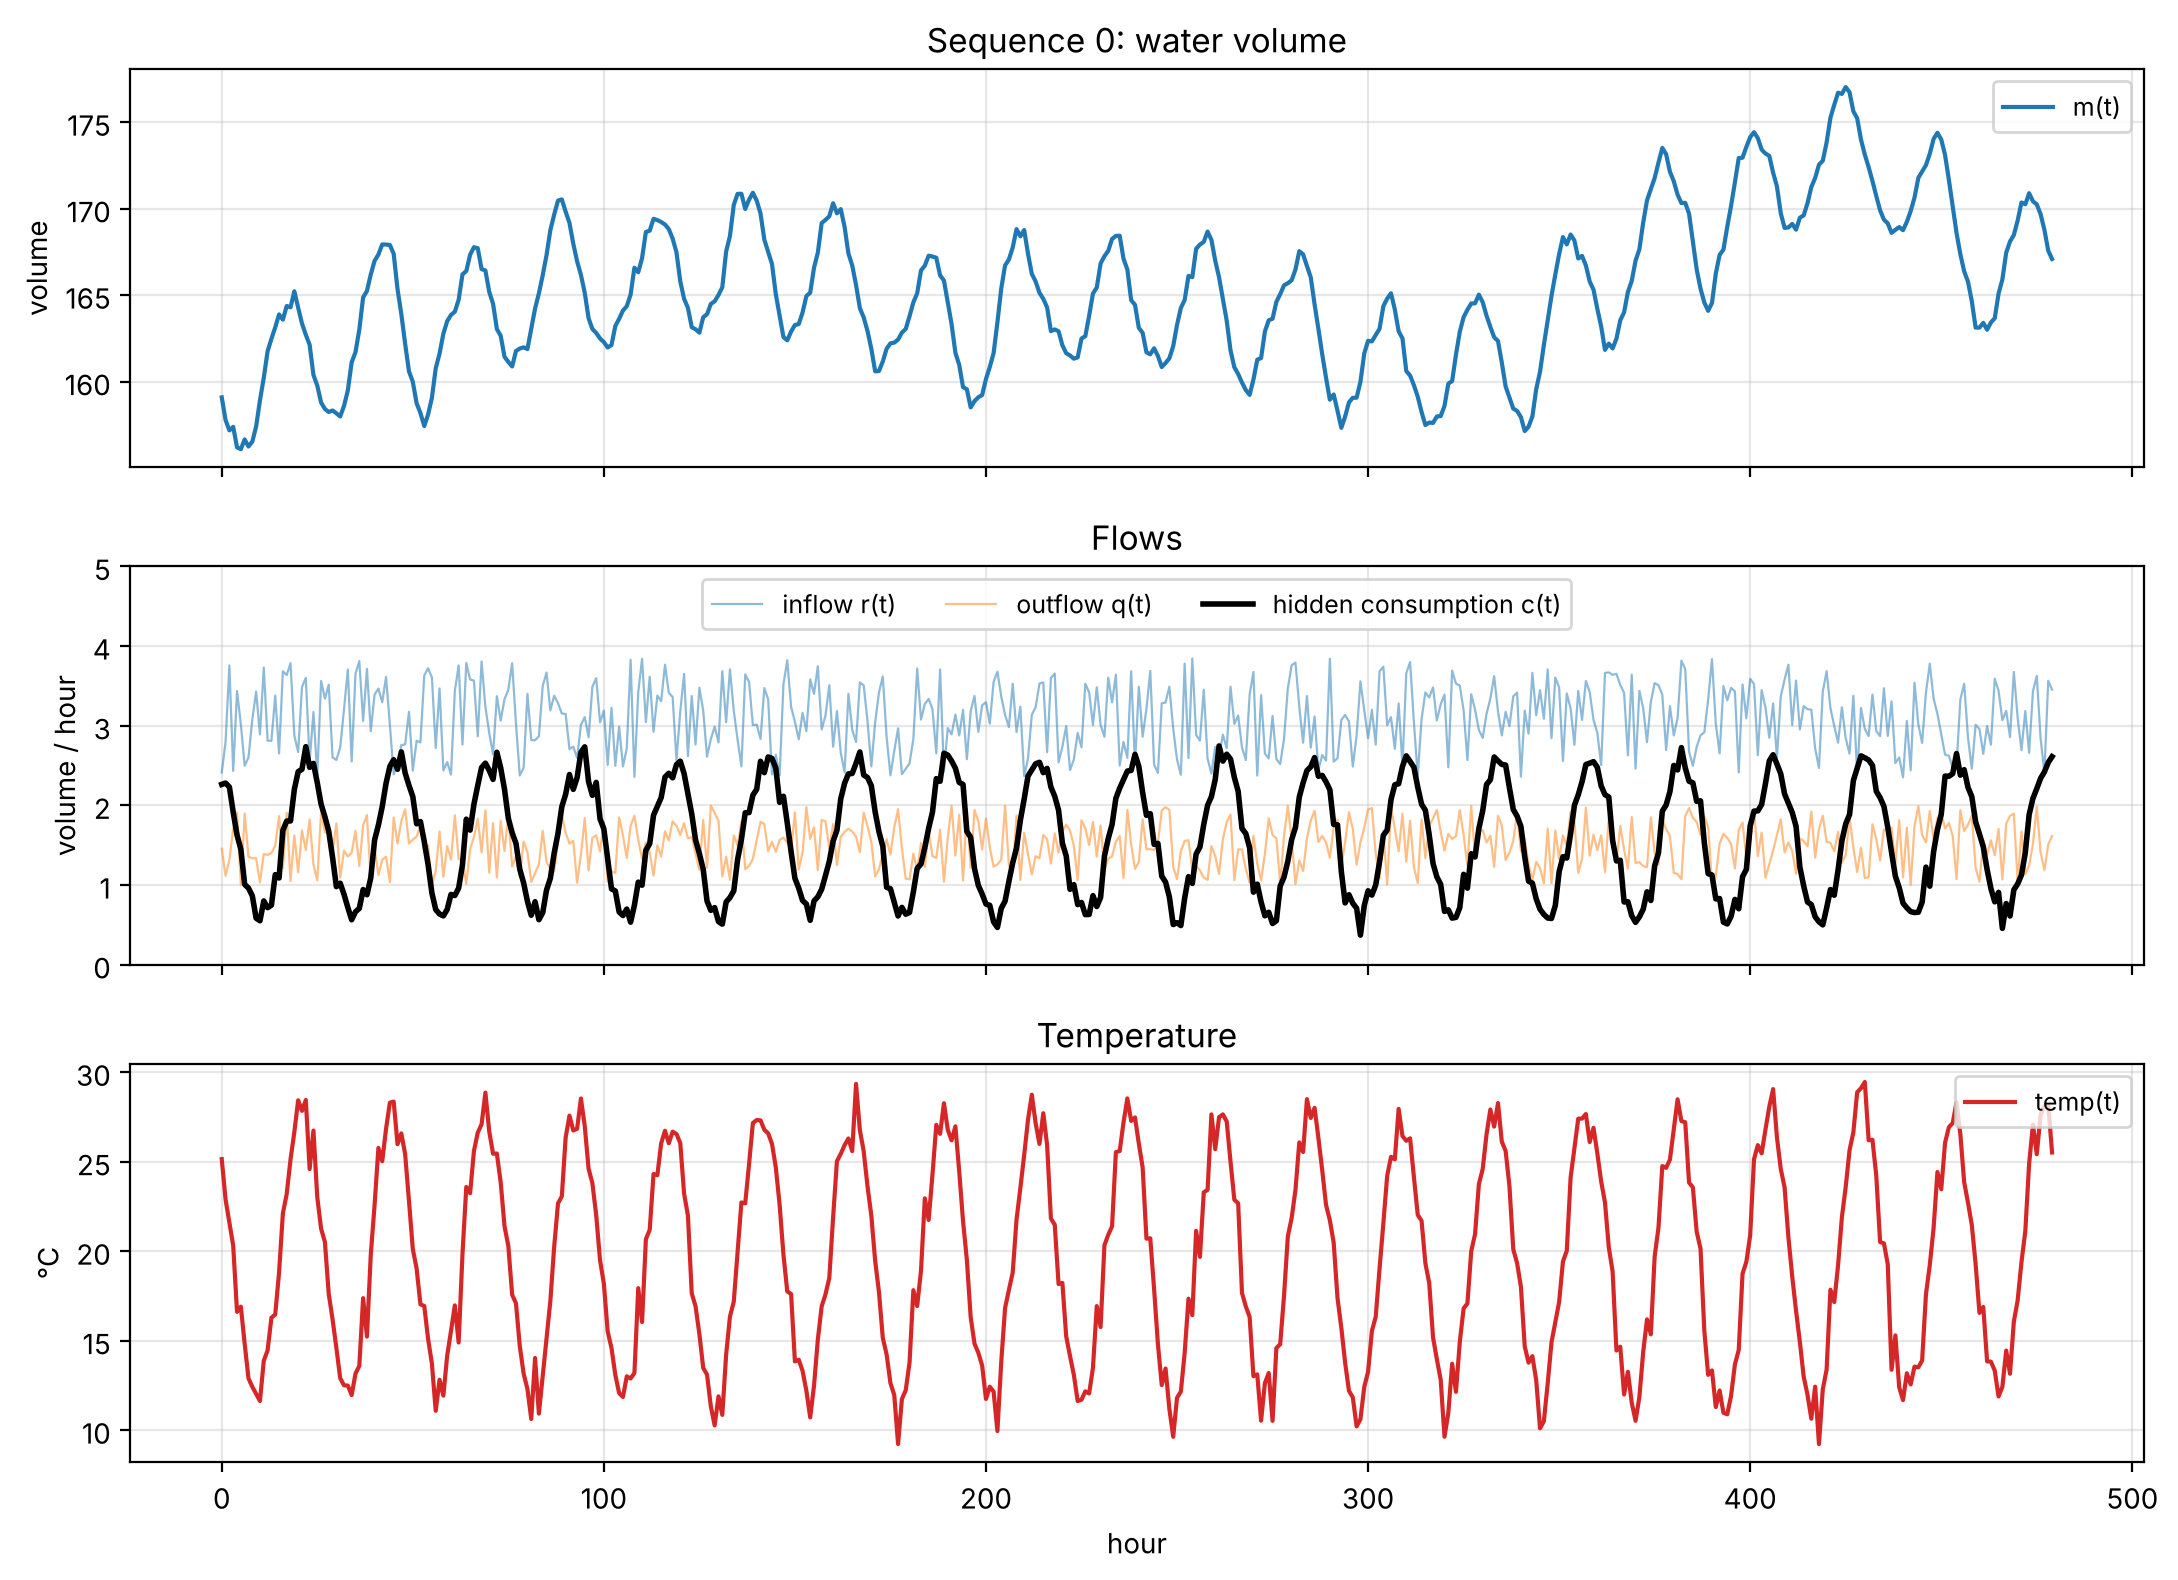

m    range: 80.3 – 250.3
c    range: 0.151 – 3.011
temp range: 6.0 – 33.2 °C


In [6]:
seq = 0
hours = np.arange(CONFIG["T"])
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(hours, X[seq, :, 0], color="tab:blue", label="m(t)")
axes[0].set(title=f"Sequence {seq}: water volume", ylabel="volume")

axes[1].plot(hours, X[seq, :, 1], lw=0.8, alpha=0.5, label="inflow r(t)")
axes[1].plot(hours, X[seq, :, 2], lw=0.8, alpha=0.5, label="outflow q(t)")
axes[1].plot(hours, C[seq], lw=2.0, color="black", label="hidden consumption c(t)")
axes[1].set(title="Flows", ylabel="volume / hour", ylim=(0, 5))
axes[1].legend(loc="upper center", ncol=3, fontsize=9)

axes[2].plot(hours, X[seq, :, 3], color="tab:red", label="temp(t)")
axes[2].set(title="Temperature", ylabel="°C", xlabel="hour")

for ax in axes:
    ax.grid(alpha=0.3)
    if ax.get_legend() is None:
        ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

print(f"m    range: {float(X[..., 0].min()):.1f} – {float(X[..., 0].max()):.1f}")
print(f"c    range: {float(C.min()):.3f} – {float(C.max()):.3f}")
print(f"temp range: {float(X[..., 3].min()):.1f} – {float(X[..., 3].max()):.1f} °C")

assert len(axes) == 3
assert all(ax.get_title() and ax.get_ylabel() and ax.get_legend() is not None for ax in axes)

**Split and normalize.** Split train/test **by sequence**, not by timestep, so no timesteps from a test sequence leak into training through shared history. Normalize inputs (zero mean, unit variance) using statistics computed **only on the training split**. Keep the *unnormalized* `m(t)`, `r(t)`, `q(t)` around separately — you'll need the raw physical values later for the conservation-law reconstruction, which must not be done in normalized units.

### 4.3 Split, normalization and the shifted test set ★

`make_dataset` returns a **bundle**, a dictionary with everything a model needs:

- **Split by sequence:** sequences 0–299 for training (or only the first `n_train` of them), 300–349 for validation, 350–449 for test. A validation set is added to the template's train/test split so that every choice made during training (the best epoch in section 7, `μ` in 8E.1) uses validation data, and the test set is only measured.
- **Statistics from the training sequences actually used**, computed in float64: `x_mean`, `x_std` for the inputs and `y_mean`, `y_std` for the target (used to scale the baseline's output, section 5). With `n_train = 25`, the statistics come from those 25 sequences only.
- **Normalized inputs `Xn_*`** for the networks, and the **raw `X_*`** kept, because the mass balance must use the unnormalized `m, r, q`.

`DATA` is the main bundle. `DATA_SHIFT` is the same data generated 15 °C colder — a **cold spell** — and normalized with `DATA`'s statistics, because a trained model must see new inputs through the normalization it was trained with (recomputing statistics on the cold data would hide the shift from the model). Only its test split is used, in section 8. In the cold spell the consumption is lower and often clipped at zero, which puts the true volume close to the physical boundary `m(t+1) ≤ m + r − q`.

In [7]:
seq_ids = {
    "train": np.arange(0, CONFIG["n_train"]),
    "val":   np.arange(CONFIG["n_train"], CONFIG["n_train"] + CONFIG["n_val"]),
    "test":  np.arange(CONFIG["n_train"] + CONFIG["n_val"], CONFIG["n_seq"]),
}


def make_dataset(key, n_train=CONFIG["n_train"], temp_shift=0.0, stats_from=None, tag="main"):
    """Generate the data and return a bundle split by sequence.

    key        : data key (the same key gives the same sequences)
    n_train    : how many of the 300 training sequences to use (the first n_train)
    temp_shift : temperature shift in °C (cold spell: -15)
    stats_from : another bundle whose normalization statistics are reused, or None
    tag        : short label of the bundle
    Returns a dict with X_*/Y_*/C_* (raw), Xn_* (normalized), x_mean, x_std (6,),
    y_mean, y_std (floats) and tag, for * in {tr, va, te}.
    """
    X, Y, C = generate_data(key, CONFIG["n_seq"], CONFIG["T"], temp_shift)
    tr, va, te = seq_ids["train"][:n_train], seq_ids["val"], seq_ids["test"]
    d = {"tag": tag}
    for s, ids in (("tr", tr), ("va", va), ("te", te)):
        d[f"X_{s}"], d[f"Y_{s}"], d[f"C_{s}"] = X[ids], Y[ids], C[ids]

    if stats_from is None:
        x64 = np.asarray(d["X_tr"], dtype=np.float64)
        y64 = np.asarray(d["Y_tr"], dtype=np.float64)
        d["x_mean"] = x64.mean(axis=(0, 1)).astype(np.float32)
        d["x_std"] = x64.std(axis=(0, 1)).astype(np.float32)
        d["y_mean"], d["y_std"] = float(y64.mean()), float(y64.std())
    else:   # reuse the statistics a model was trained with
        for k in ("x_mean", "x_std", "y_mean", "y_std"):
            d[k] = stats_from[k]

    for s in ("tr", "va", "te"):
        d[f"Xn_{s}"] = ((d[f"X_{s}"] - d["x_mean"]) / d["x_std"]).astype(jnp.float32)
    return d


DATA = make_dataset(data_key)
DATA_SHIFT = make_dataset(data_key, temp_shift=CONFIG["temp_shift"], stats_from=DATA, tag="shift")

print("train / val / test:", DATA["X_tr"].shape, DATA["X_va"].shape, DATA["X_te"].shape)
xn64 = np.asarray(DATA["Xn_tr"], dtype=np.float64)
print("normalized train mean:", np.round(xn64.mean(axis=(0, 1)), 4))
print("normalized train std :", np.round(xn64.std(axis=(0, 1)), 4))
print(f"y_mean = {DATA['y_mean']:.2f}, y_std = {DATA['y_std']:.2f}")
shift_c0 = float(jnp.mean(DATA_SHIFT["C_te"] == 0))
print(f"Cold-spell test set: steps with c = 0: {100 * shift_c0:.1f} % "
      f"(main test set: {100 * float(jnp.mean(DATA['C_te'] == 0)):.1f} %)")

assert DATA["X_tr"].shape[0] == 300 and DATA["X_va"].shape[0] == 50 and DATA["X_te"].shape[0] == 100
assert (len(set(seq_ids["train"]) | set(seq_ids["val"]) | set(seq_ids["test"])) == CONFIG["n_seq"])
assert np.allclose(xn64.mean(axis=(0, 1)), 0, atol=1e-3) and np.allclose(xn64.std(axis=(0, 1)), 1, atol=1e-3)
full_mean = np.asarray(X, dtype=np.float64).mean(axis=(0, 1))
assert not np.allclose(DATA["x_mean"], full_mean, rtol=0, atol=1e-6)   # train-only statistics
small = make_dataset(data_key, n_train=25, tag="check")
for k in ("X_va", "Y_va", "X_te", "Y_te"):
    assert bool(jnp.array_equal(small[k], DATA[k]))
assert np.array_equal(DATA_SHIFT["x_mean"], DATA["x_mean"])
assert bool(jnp.allclose(DATA_SHIFT["X_te"][..., 3], DATA["X_te"][..., 3] - 15.0, atol=1e-4))
del small

train / val / test: (300, 480, 6) (50, 480, 6) (100, 480, 6)
normalized train mean: [ 0.  0. -0. -0.  0. -0.]
normalized train std : [1. 1. 1. 1. 1. 1.]
y_mean = 156.48, y_std = 16.72
Cold-spell test set: steps with c = 0: 14.4 % (main test set: 0.0 %)


<a id='5'></a>
## 5. Task 5.2 — Conventional LSTM (the baseline, Option 1)

A standard LSTM that receives the observable variables and **predicts the mass directly**:

$$ \hat{m}(t+1) = \text{LSTM}_\theta\big(x(t)\big) $$

It has no knowledge of the conservation law — it has to learn everything from data. This is your baseline.

### Implementation notes ★

- **Many-to-many prediction.** `nn.RNN` unrolls one `nn.LSTMCell` over the 480 steps and returns the hidden state at *every* step, shape (B, T, 32). A `Dense(1)` applied to each hidden state gives one prediction per step, so the network predicts `m(t+1)` at every hour from everything it has seen up to `t`.
- **Initialization.** Flax initializes the input weights of the LSTM with a Lecun-normal scheme and the recurrent weights as orthogonal matrices; orthogonal recurrent weights keep the hidden state from shrinking or exploding over long sequences at the start of training.
- **Output scaling, outside the module.** The target is around 150 with a standard deviation `y_std`, while a freshly initialized network outputs values of order 1. The baseline's output is therefore read as a normalized volume and mapped back with `m̂ = y_mean + y_std · output` (in `build_model`, section 6). Without it the baseline would spend its training learning an offset of 150, and the comparison with Option 4 would measure output scaling rather than physics. The mapping stays outside the module so that the module is a plain LSTM regressor and the statistics stay in the data bundle.
- **Parameters.** The LSTM cell has four gates, each with input weights (6 × 32, no bias) and recurrent weights with bias (32 × 32 + 32): 4 · (192 + 1,056) = 4,992. The output layer adds 32 + 1 = 33, so 5,025 in total.

The check runs the untrained model on two training sequences and shows the hidden states it produces.

In [8]:
class LSTMBackbone(nn.Module):
    """Recurrent LSTM layer returning the hidden state at every step.

    xs : (batch, T, features) -> (batch, T, hidden_size)
    """
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs):                     # xs: (batch, T, features)
        return nn.RNN(nn.LSTMCell(features=self.hidden_size))(xs)


class ConventionalLSTM(nn.Module):
    """Predicts m(t+1) directly (normalized output; scaled in build_model).

    xs : (batch, T, 6) normalized inputs -> (batch, T)
    """
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs):                     # xs (normalized): (batch, T, 6)
        h = LSTMBackbone(self.hidden_size)(xs)
        return nn.Dense(1)(h).squeeze(-1)


def n_parameters(params):
    """Total number of scalar parameters in a parameter pytree."""
    return int(sum(p.size for p in jax.tree_util.tree_leaves(params)))


# Check: hidden states and output of the untrained baseline on two training sequences.
check_model = ConventionalLSTM(CONFIG["hidden_size"])
check_params = check_model.init(run_key("check5_s112358"), DATA["Xn_tr"][:2])
out, state = check_model.apply(check_params, DATA["Xn_tr"][:2],
                               capture_intermediates=lambda mdl, _: isinstance(mdl, LSTMBackbone))
hidden = state["intermediates"]["LSTMBackbone_0"]["__call__"][0]
print("hidden states:", hidden.shape, " output:", out.shape)
print("hidden state of sequence 0 at t = 0, 1, 479 (first 4 units):")
print(np.round(np.asarray(hidden[0, [0, 1, -1], :4]), 3))
print("parameters:", n_parameters(check_params))

assert hidden.shape == (2, 480, 32) and out.shape == (2, 480)
assert n_parameters(check_params) == 5025
del check_model, check_params, out, state, hidden

hidden states: (2, 480, 32)  output: (2, 480)
hidden state of sequence 0 at t = 0, 1, 479 (first 4 units):
[[ 0.213  0.076  0.072 -0.115]
 [ 0.403  0.097 -0.112 -0.394]
 [-0.025  0.387  0.054  0.175]]
parameters: 5025


<a id='6'></a>
## 6. Task 5.3 — Your model (the option your group chose in Phase A)

Implement **one** of the three non-baseline options from Phase A §2 — whichever your group chose and justified in Discussion 3. You only need the one matching your choice; the other two stubs below are there for reference (or if you want to compare more than one — optional, not required).

**Important, for all three options:** the model should receive `xs` **normalized** for the neural-network part, but must use the **original physical values** of `m`, `r`, `q` wherever the mass balance is used (reconstruction, or the physics loss term) — doing that arithmetic in normalized units would be physically meaningless.

### Option 2 — Soft constraint (not implemented)

The network would output both `m̂(t+1)` and `ĉ(t)`, and the loss would add `λ · (m̂(t+1) − m(t) − r(t) + q(t) + ĉ(t))²` to the prediction error. The physics enters only through the loss, so conservation is encouraged but never guaranteed, nothing keeps `ĉ ≥ 0`, and `λ` must be tuned with several training runs. Phase A (Discussion 3) ranked it below Options 3 and 4 for these reasons, so it is not coded here.

### Option 3 — Hard constraint (not implemented)

The network would predict only `ĉ(t) = softplus(·) ≥ 0`, and the mass would be reconstructed as `m̂(t+1) = m(t) + r(t) − q(t) − ĉ(t)`, so conservation holds exactly by construction. Phase A (Discussion 3) preferred Option 4 because a real balance is rarely complete: when there is an unmetered gain, Option 3 must push every mismatch into `ĉ`, and `ĉ ≥ 0` cannot represent a net gain. Option 4 is Option 3 plus a correction head, so it is the only physics model coded here.

### Option 4 — Residual correction

Like Option 3, but the network also predicts a small correction `δ(t)` to absorb unmodelled effects:

$$ \hat{m}(t+1) = m(t) + r(t) - q(t) - \hat{c}(t) + \delta(t) $$

Useful if you think the conservation law alone doesn't fully capture the true dynamics — but conservation is no longer exact, so watch how large `δ(t)` grows in §8's physical-error metric.

### Implementation of Option 4 ★

- **Two heads on one backbone:** `head_c` → `softplus` gives `ĉ(t) > 0`; `head_delta` gives the correction `δ(t)` with no constraint. They share the same LSTM, which adds only 33 parameters to the baseline (5,058 in total).
- **The balance in raw units:** `m̂(t+1) = ((m + r) − q) − ĉ + δ`, with the unnormalized `m, r, q` passed as separate arguments. The order of operations is fixed so that the metrics of section 8 can rebuild the same value.
- **What the network learns:** only the small terms `ĉ` and `δ` (of order 1), while the large, easy part of the target (`m + r − q`, about 150) is given by the physics. That is the inductive bias.
- **Identifiability:** only `ĉ − δ` enters `m̂`. Under a plain MSE, a larger `ĉ` and a larger `δ` give the same prediction, so the loss cannot tell them apart. Section 8 therefore judges the *effective* consumption `ĉ − δ`, and experiment 8E.1 tests a penalty that makes the split identifiable.

The check runs the untrained model and verifies the balance and the positivity of `ĉ`.

In [9]:
class ResidualCorrectionLSTM(nn.Module):
    """Option 4: hard constraint plus a small learned correction delta(t).

    xs_norm                : (batch, T, 6) normalized network input
    m_phys, r_phys, q_phys : (batch, T) RAW physical values
    Returns (m_pred, c_hat, delta), each (batch, T); m_pred in physical units.
    """
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs_norm, m_phys, r_phys, q_phys):
        h = LSTMBackbone(self.hidden_size)(xs_norm)
        c_hat = nn.softplus(nn.Dense(1, name="head_c")(h).squeeze(-1))   # hidden consumption > 0
        delta = nn.Dense(1, name="head_delta")(h).squeeze(-1)            # correction, unconstrained
        m_pred = ((m_phys + r_phys) - q_phys) - c_hat + delta            # balance, raw units, fixed order
        return m_pred, c_hat, delta


# Check on two training sequences, untrained.
check_model = ResidualCorrectionLSTM(CONFIG["hidden_size"])
xs, xr = DATA["Xn_tr"][:2], DATA["X_tr"][:2]
check_params = check_model.init(run_key("check6_s112358"), xs, xr[..., 0], xr[..., 1], xr[..., 2])
m_pred, c_hat, delta = check_model.apply(check_params, xs, xr[..., 0], xr[..., 1], xr[..., 2])
balance = ((xr[..., 0] + xr[..., 1]) - xr[..., 2]) - c_hat + delta
gap = float(jnp.max(jnp.abs(m_pred - balance)))
print("m_pred:", m_pred.shape, " c_hat:", c_hat.shape, " delta:", delta.shape)
print("parameters:", n_parameters(check_params))
print(f"min c_hat = {float(c_hat.min()):.4f},  max |m_pred - balance| = {gap:.1e}")

assert m_pred.shape == c_hat.shape == delta.shape == (2, 480)
assert n_parameters(check_params) == 5058
assert bool(jnp.all(c_hat > 0)) and gap < 1e-3
del check_model, check_params, xs, xr, m_pred, c_hat, delta, balance

m_pred: (2, 480)  c_hat: (2, 480)  delta: (2, 480)
parameters: 5058
min c_hat = 0.4268,  max |m_pred - balance| = 0.0e+00


### A uniform interface for the two models

The two models take different arguments and return different things. `build_model(kind, data)` hides this so that training and evaluation are written once:

- `init_fn(key)` initializes the parameters with one training sequence as a dummy input;
- `predict_fn(params, xn, x_raw)` returns `(m_pred, c_hat, delta)` in physical units — for the baseline `m_pred = y_mean + y_std · output` and `c_hat = delta = None`.

`xn` is the normalized input of the network, `x_raw` the raw one, from which Option 4 takes `m, r, q`.

In [10]:
def build_model(kind, data):
    """Build a model and its functions.

    kind : "baseline" or "option4"
    data : bundle (provides y_mean, y_std and a dummy input)
    Returns (model, init_fn, predict_fn):
      init_fn(key) -> params
      predict_fn(params, xn (B, T, 6), x_raw (B, T, 6)) -> (m_pred, c_hat, delta),
      each (B, T) in physical units; c_hat = delta = None for the baseline.
    """
    hidden = CONFIG["hidden_size"]
    if kind == "baseline":
        model = ConventionalLSTM(hidden)
        y_mean, y_std = data["y_mean"], data["y_std"]

        def init_fn(key):
            return model.init(key, data["Xn_tr"][:1])

        def predict_fn(params, xn, x_raw):
            return y_mean + y_std * model.apply(params, xn), None, None

    elif kind == "option4":
        model = ResidualCorrectionLSTM(hidden)

        def init_fn(key):
            x1 = data["X_tr"][:1]
            return model.init(key, data["Xn_tr"][:1], x1[..., 0], x1[..., 1], x1[..., 2])

        def predict_fn(params, xn, x_raw):
            return model.apply(params, xn, x_raw[..., 0], x_raw[..., 1], x_raw[..., 2])

    else:
        raise ValueError(f"unknown model kind: {kind}")
    return model, init_fn, predict_fn


for kind in ("baseline", "option4"):
    _, init_fn, predict_fn = build_model(kind, DATA)
    p = init_fn(run_key(f"check_iface_{kind}_s112358"))
    m_pred, c_hat, delta = predict_fn(p, DATA["Xn_tr"][:2], DATA["X_tr"][:2])
    print(f"{kind:9s}: m_pred {m_pred.shape}, mean {float(m_pred.mean()):.2f} "
          f"(y_mean {DATA['y_mean']:.2f}), c_hat {'None' if c_hat is None else c_hat.shape}")
    assert m_pred.shape == (2, 480)
    assert abs(float(m_pred.mean()) - DATA["y_mean"]) < 2 * DATA["y_std"]
    assert (c_hat is None) == (kind == "baseline")
del p, m_pred, c_hat, delta

baseline : m_pred (2, 480), mean 156.81 (y_mean 156.48), c_hat None


option4  : m_pred (2, 480), mean 177.09 (y_mean 156.48), c_hat (2, 480)


<a id='7'></a>
## 7. Task 5.4 — Train the baseline model and your model under identical conditions

- **Baseline (§5, Option 1):** MSE on `m(t+1)` directly.
- **Your model (§6):** the loss depends on which option you implemented —
  - **Option 2 (soft constraint):** `L = L_pred + λ·L_physics` (§6). `λ` is an extra hyperparameter — try a few values (e.g. `0.1, 1.0, 10.0`) and see how it trades off prediction accuracy against conservation.
  - **Option 3 (hard constraint) / Option 4 (residual correction):** MSE on the *reconstructed* `m̂(t+1)`, not on `ĉ(t)` directly — the true `c(t)` must not be used for supervision.
- Same optimizer, learning rate, hidden size, and number of epochs for both models — otherwise you're no longer measuring the effect of the architecture alone. Reasonable starting values: `hidden_size=32`, `Adam(learning_rate=1e-2)`, `~300` epochs, `batch_size=32` sequences.
- **Use mini-batch training**: at each step, sample (or shuffle-and-slice) a batch of `batch_size` sequences from the training set rather than using all sequences at once. Reshuffle sequence order at the start of every epoch, using `jax.random.permutation` (splitting your key each time) so the shuffling stays reproducible.
- Wrap the training step in `jax.jit` and record training time for both models.
- Plot training loss curves for both on the same axes (log scale is usually clearer).

### How training works here ★

- **Mini-batches of whole sequences.** Each step uses 32 complete sequences of 480 hours, so the LSTM always sees each sequence from its start. Every epoch the order of the training sequences is reshuffled with `jax.random.permutation`, using a key freshly split from the run's key: the shuffling is different every epoch but identical every time the notebook runs. With 300 sequences an epoch is 9 batches of 32 and one of 12; the last, smaller batch is kept so that every sequence is used every epoch.
- **Loss in physical units.** Both models minimize the MSE of `m(t+1)` in the original volume units, so their losses are directly comparable.
- **Gradient clipping.** Before each Adam update the gradient is rescaled if its global norm exceeds 1.0 (`optax.clip_by_global_norm`). Back-propagating through 480 LSTM steps can occasionally produce very large gradients; clipping limits the size of one update without changing its direction. It is applied to both models alike.
- **Best epoch on validation.** After every epoch the validation MSE is computed, and training returns the parameters of the epoch where it was lowest. All 300 epochs always run, so the training times stay comparable.
- **`C` is in no batch.** A batch holds only the normalized input `xn`, the raw input `x` (for the balance) and the target `y`. The true consumption is never seen by a model or a loss.
- **Compilation.** `make_train_step` wraps one step in `jax.jit`; the step is built once per run and compiled for the two batch shapes.

In [11]:
def make_train_step(loss_fn, optimizer):
    @jax.jit
    def step(params, opt_state, batch):
        loss, grads = jax.value_and_grad(loss_fn)(params, batch)
        updates, opt_state = optimizer.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)
        return params, opt_state, loss
    return step

HIDDEN_SIZE = CONFIG["hidden_size"]
EPOCHS = CONFIG["epochs"]
BATCH_SIZE = CONFIG["batch_size"]
# Clip the global gradient norm, then Adam: the same optimizer for every run.
optimizer = optax.chain(optax.clip_by_global_norm(CONFIG["clip_norm"]),
                        optax.adam(CONFIG["learning_rate"]))


def make_batch(X_xs, extra_arrays, y, idx):
    """Select the sequences idx: {"xn": X_xs[idx], "y": y[idx], plus each extra array}."""
    return {"xn": X_xs[idx], "y": y[idx], **{k: v[idx] for k, v in extra_arrays.items()}}


def make_loss_fn(predict_fn, mu=0.0):
    """Loss = MSE of m(t+1) in physical units, + mu * mean(delta^2) if mu > 0 and the model has delta."""
    def loss_fn(params, batch):
        m_pred, _, delta = predict_fn(params, batch["xn"], batch["x"])
        loss = jnp.mean((m_pred - batch["y"]) ** 2)
        if mu > 0 and delta is not None:      # decided in Python when the function is traced
            loss = loss + mu * jnp.mean(delta ** 2)
        return loss
    return loss_fn


def make_val_fn(predict_fn, data):
    """Jitted validation MSE (no penalty) of params on data's validation split."""
    @jax.jit
    def val_fn(params):
        m_pred, _, _ = predict_fn(params, data["Xn_va"], data["X_va"])
        return jnp.mean((m_pred - data["Y_va"]) ** 2)
    return val_fn


def train_model(model, params, loss_fn, key, X_xs, extra_arrays, y, epochs=EPOCHS, batch_size=BATCH_SIZE,
                val_fn=None):
    """Mini-batch training with per-epoch reshuffling and best-epoch selection.

    model        : unused (kept for the template's signature)
    X_xs         : (N, T, 6) normalized inputs;  y : (N, T) targets
    extra_arrays : dict of other per-sequence arrays the loss needs (here {"x": raw inputs})
    val_fn       : params -> validation MSE, or None (then the last epoch is returned)
    Returns (best_params, history) with history = {"train": [...], "val": [...], "best_epoch": int, 1-based}.
    """
    step = make_train_step(loss_fn, optimizer)
    opt_state = optimizer.init(params)
    n = X_xs.shape[0]
    history = {"train": [], "val": []}
    best_val, best_params, best_epoch = np.inf, params, epochs

    for epoch in range(1, epochs + 1):
        key, k_perm = jax.random.split(key)             # a fresh key for every shuffle
        perm = jax.random.permutation(k_perm, n)
        total = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            params, opt_state, loss = step(params, opt_state, make_batch(X_xs, extra_arrays, y, idx))
            total += float(loss) * len(idx)              # weight by batch size (last batch is smaller)
        history["train"].append(total / n)

        if val_fn is not None:
            val = float(val_fn(params))
            history["val"].append(val)
            if val < best_val:
                best_val, best_params, best_epoch = val, params, epoch

    if val_fn is None:
        best_params = params
    history["best_epoch"] = best_epoch
    return best_params, history

### Runs and cache

`run_experiment` trains one model from scratch: it builds the model, draws two keys from `run_key(name)` (initialization and shuffling), trains it, and returns the loss histories, the best epoch, the training time (`time.time()` around the whole training, compilation included, as a real user would wait for it), the parameter count and the test predictions — and, when asked, the predictions on another bundle such as the cold spell. The trained parameters are not kept; the predictions are enough for every metric.

`run_cached` saves each result in `results/<name>.npz` and loads it on the next run of the notebook, so that changing a plot or a text does not retrain 13 models. It records every run in `RUNS` (used by the final checks) and prints one line per run. After a change in the code, delete `results/`.

In [12]:
RUNS = {}


def run_experiment(name, kind, data, mu=0.0, eval_sets=None, seed=CONFIG["seed"]):
    """Train one model and return its results as NumPy arrays / Python numbers.

    name      : run name, which determines its PRNG key
    kind      : "baseline" or "option4";  data : training bundle
    mu        : weight of the delta penalty (0 = plain MSE)
    eval_sets : {prefix: bundle} of extra test splits to predict on, or None
    Returns a dict: train_loss, val_loss (epochs,), best_epoch, time, n_params, kind, mu,
    and <prefix>_m_pred [, <prefix>_c_hat, <prefix>_delta] (n_test, T) for "test" and each eval set.
    """
    model, init_fn, predict_fn = build_model(kind, data)
    k_init, k_train = jax.random.split(run_key(name, seed))
    params = init_fn(k_init)

    t0 = time.time()
    best_params, history = train_model(model, params, make_loss_fn(predict_fn, mu), k_train,
                                       data["Xn_tr"], {"x": data["X_tr"]}, data["Y_tr"],
                                       val_fn=make_val_fn(predict_fn, data))
    elapsed = time.time() - t0

    out = {"train_loss": np.array(history["train"]), "val_loss": np.array(history["val"]),
           "best_epoch": history["best_epoch"], "time": elapsed, "n_params": n_parameters(params),
           "kind": kind, "mu": mu}
    predict = jax.jit(predict_fn)
    for prefix, bundle in {"test": data, **(eval_sets or {})}.items():
        m_pred, c_hat, delta = predict(best_params, bundle["Xn_te"], bundle["X_te"])
        out[f"{prefix}_m_pred"] = np.asarray(m_pred)
        if c_hat is not None:
            out[f"{prefix}_c_hat"], out[f"{prefix}_delta"] = np.asarray(c_hat), np.asarray(delta)
    return out


def run_cached(name, kind, data, mu=0.0, eval_sets=None, seed=CONFIG["seed"]):
    """run_experiment with a cache in results/<name>.npz; records the run in RUNS."""
    path = os.path.join("results", f"{name}.npz")
    if CONFIG["use_cache"] and os.path.exists(path):
        with np.load(path) as f:
            result = {k: (f[k].item() if f[k].ndim == 0 else f[k]) for k in f.files}
        status = "loaded from cache"
    else:
        result = run_experiment(name, kind, data, mu, eval_sets, seed)
        np.savez(path, **result)
        status = "computed"
    RUNS[name] = {"kind": kind, "tag": data["tag"], "mu": mu, "seed": seed}
    print(f"{name}: {status}")
    return result

### Main runs

The baseline and Option 4, trained under identical settings on `DATA`. Both also predict on the cold-spell test set, used in section 8. Their losses are shown below; their training times are in section 8's table.

In [13]:
seed = CONFIG["seed"]
RESULTS = {}
RESULTS["baseline"] = run_cached(f"baseline_s{seed}", "baseline", DATA, eval_sets={"shift": DATA_SHIFT})
RESULTS["opt4"] = run_cached(f"opt4_s{seed}", "option4", DATA, eval_sets={"shift": DATA_SHIFT})

baseline_s112358: computed


opt4_s112358: computed


### Loss curves

Training loss (solid) and validation MSE (dashed) of both models on log–log axes; the dot marks the epoch whose parameters are kept. The line under the plot gives, per model, the first and last training loss and the best epoch with its validation MSE.

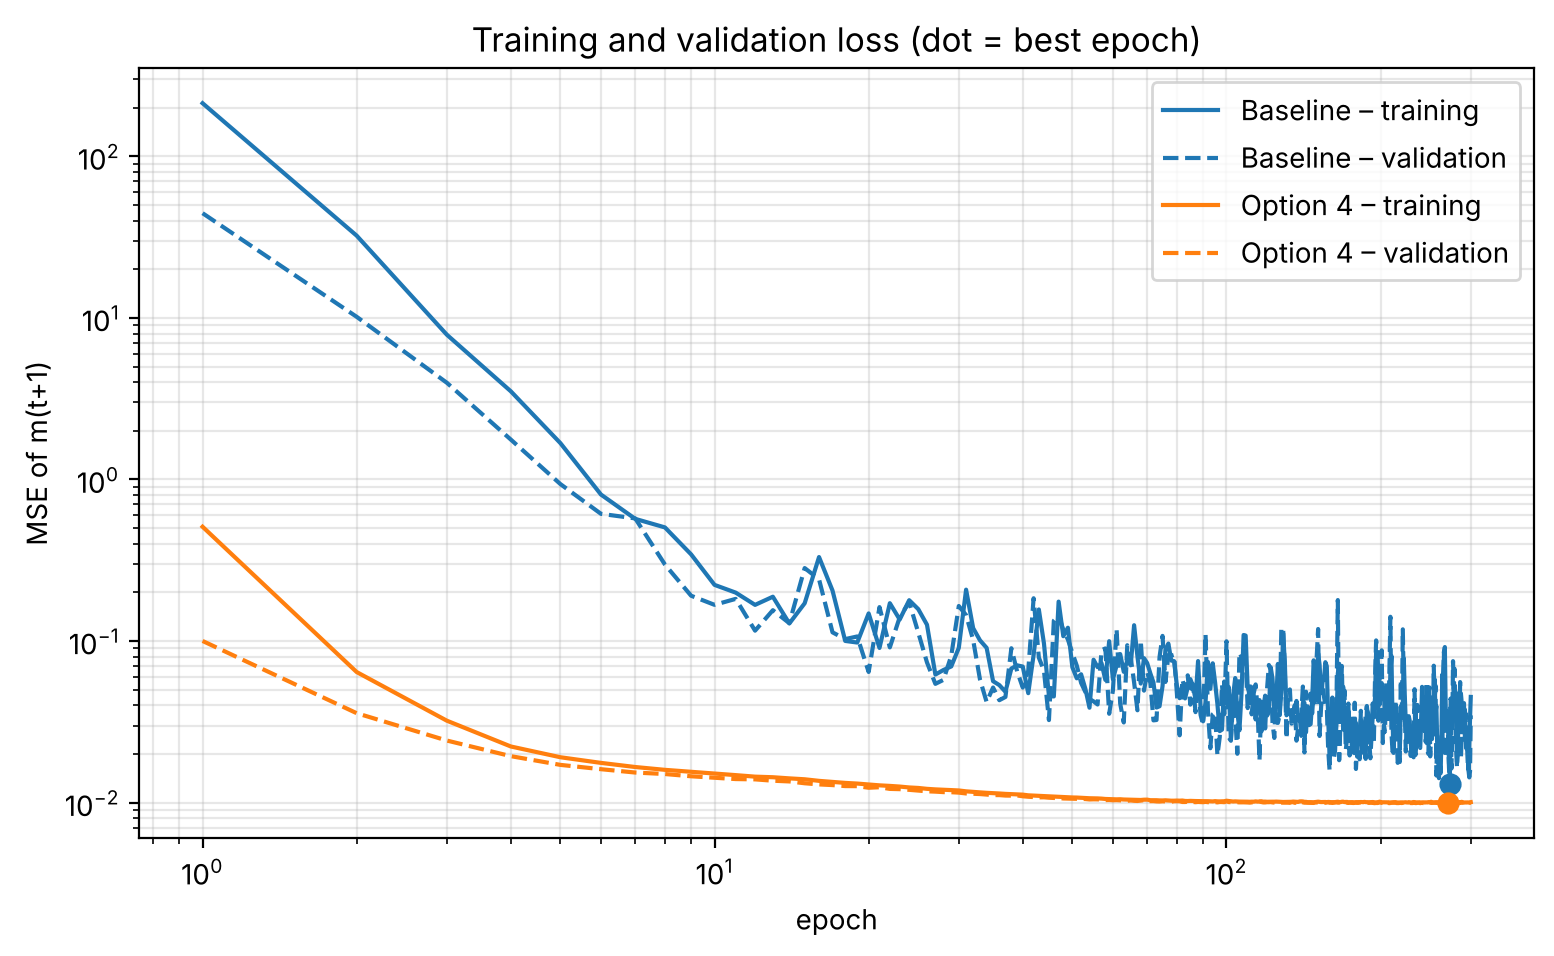

Baseline : training loss 213 → 0.04511; best epoch 273, validation MSE 0.01309
Option 4 : training loss 0.5097 → 0.01007; best epoch 271, validation MSE 0.009917


In [14]:
LABELS = {"baseline": "Baseline", "opt4": "Option 4"}
COLORS = {"baseline": "tab:blue", "opt4": "tab:orange"}


def plot_losses(runs):
    """Plot training (solid) and validation (dashed) losses of each run; print one line per run.

    runs : {key in LABELS: result dict of run_cached}
    """
    fig, ax = plt.subplots(figsize=(9, 5))
    for label, res in runs.items():
        epochs = np.arange(1, len(res["train_loss"]) + 1)
        be = int(res["best_epoch"])
        ax.plot(epochs, res["train_loss"], color=COLORS[label], label=f"{LABELS[label]} – training")
        ax.plot(epochs, res["val_loss"], "--", color=COLORS[label], label=f"{LABELS[label]} – validation")
        ax.plot(be, res["val_loss"][be - 1], "o", color=COLORS[label], ms=7)
    ax.set(xscale="log", yscale="log", xlabel="epoch", ylabel="MSE of m(t+1)",
           title="Training and validation loss (dot = best epoch)")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
    plt.show()
    for label, res in runs.items():
        be = int(res["best_epoch"])
        print(f"{LABELS[label]:9s}: training loss {res['train_loss'][0]:.4g} → {res['train_loss'][-1]:.4g}; "
              f"best epoch {be}, validation MSE {res['val_loss'][be - 1]:.4g}")


plot_losses(RESULTS)

### Conclusion of section 7

- **Starting point.** The baseline starts with a training loss of 213, Option 4 with 0.5097. Option 4 starts low because its prediction is already `m + r − q` minus a consumption of the right order before any training; the baseline has to learn the whole volume.
- **End point.** After 300 epochs the training loss is 0.04511 for the baseline and 0.01007 for Option 4. Option 4's curves flatten after about 100 epochs, close to 0.01, the variance of the consumption noise that no model can predict.
- **Stability.** Option 4's validation curve is smooth and lies on its training curve. The baseline's jumps by up to an order of magnitude from one epoch to the next even late in training, so its last epoch is partly a matter of luck.
- **Best-epoch selection.** It keeps epoch 273 for the baseline (validation MSE 0.01309, against a last training loss of 0.04511) and epoch 271 for Option 4 (0.009917). For the baseline the selection matters; for Option 4 it changes almost nothing, because its curve is flat.

<a id='8'></a>
## 8. Metrics and comparison

Compute all four metrics on the **held-out test set** for both models:

| Metric | Formula |
|---|---|
| **MSE** | `mean((m̂(t+1) - m(t+1))^2)` |
| **MAE** | `mean(\|m̂(t+1) - m(t+1)\|)` |
| **Physical error** | `mean(max(0, -(m(t) + r(t) - q(t) - m̂(t+1))))` — magnitude of implied negative consumption |
| **Training time** | wall-clock time for the training loop |

**Expected pattern (depends on which option you implemented in §6):**
- The **baseline** (Option 1) should show a non-zero physical error — nothing stops it from implying negative consumption.
- **Option 2 (soft constraint):** physical error should be *reduced* relative to the baseline but generally still nonzero — how much depends on `λ`; larger `λ` should push it closer to zero, at some cost to MSE.
- **Option 3 (hard constraint):** physical error should be **exactly zero**, always — not just small. `softplus` guarantees `ĉ(t) ≥ 0`, so the implied consumption `m(t)+r(t)-q(t)-m̂(t+1) = ĉ(t)` can never be negative, regardless of training quality.
- **Option 4 (residual correction):** unlike Option 3, `δ(t)` has no positivity constraint, so physical error is generally nonzero — if `δ(t)` grows large, it can exceed Option 3's.

If your results don't roughly match the pattern for your chosen option, check: are both models trained under identical conditions? Does your model's mass computation (or physics loss term) use raw, unnormalized `m, r, q`? Is `c(t)` leaking into either model's inputs anywhere?

### How the models are judged ★

- **Accuracy:** MSE and MAE of `m̂(t+1)` on the 100 test sequences.
- **Physical consistency:** each prediction implies a consumption, `ĉ_implied = ((m + r) − q) − m̂(t+1)`, computed with the raw `m, r, q` and in the same order as Option 4's balance. Consumption can be zero or positive but never negative, so the error is **one-sided**: the physical error is `mean(max(0, −ĉ_implied))`, the average amount of water a model makes appear from nowhere. A positive implied consumption, even a wrong one, is physically possible and is already penalized by the MSE.
- **Violation share:** the percentage of test steps where `ĉ_implied < 0`. It says how often the law is broken; the physical error says by how much on average.
- For Option 4 the implied consumption is exactly `ĉ − δ`: it can only be negative where `δ > ĉ`. Neither model has a guarantee: a zero is a measurement on this test set.
- **Training time:** wall-clock time of the whole training, from section 7.

In [15]:
def compute_metrics(m_pred, m, r, q, y):
    """Return (mse, mae, physical_error) of predictions m_pred (any shape) against y.

    m, r, q : raw values of the same shape; the implied consumption ((m + r) - q) - m_pred is
    computed in float32 in the order of Option 4's balance, then averaged in float64.
    """
    implied = ((m + r) - q) - m_pred
    err = np.asarray(m_pred, np.float64) - np.asarray(y, np.float64)
    return (float(np.mean(err ** 2)), float(np.mean(np.abs(err))),
            float(np.mean(np.maximum(0.0, -np.asarray(implied, np.float64)))))


def violation_share(m_pred, m, r, q):
    """Fraction of steps whose implied consumption ((m + r) - q) - m_pred is negative."""
    return float(np.mean(np.asarray(((m + r) - q) - m_pred) < 0))


def evaluate(result, data, prefix="test"):
    """Metrics of a run's stored predictions <prefix>_* on data's test split.

    Returns a dict: mse, mae, phys, share; and, if the run stored c_hat, the Option 4
    diagnostics mean_delta, mean_abs_delta, max_abs_delta, mae_c (of c_hat) and mae_eff
    (of c_hat - delta) against the true C (diagnostics only, after training).
    """
    X_te = np.asarray(data["X_te"])
    m, r, q = X_te[..., 0], X_te[..., 1], X_te[..., 2]
    m_pred = result[f"{prefix}_m_pred"]
    mse, mae, phys = compute_metrics(m_pred, m, r, q, np.asarray(data["Y_te"]))
    out = {"mse": mse, "mae": mae, "phys": phys, "share": violation_share(m_pred, m, r, q)}
    if f"{prefix}_c_hat" in result:
        c_hat = result[f"{prefix}_c_hat"].astype(np.float64)
        delta = result[f"{prefix}_delta"].astype(np.float64)
        c_true = np.asarray(data["C_te"], np.float64)
        out.update(mean_delta=float(delta.mean()), mean_abs_delta=float(np.abs(delta).mean()),
                   max_abs_delta=float(np.abs(delta).max()),
                   mae_c=float(np.abs(c_hat - c_true).mean()),
                   mae_eff=float(np.abs((c_hat - delta) - c_true).mean()))
    return out


EVAL = {label: evaluate(RESULTS[label], DATA) for label in ("baseline", "opt4")}

rows = [("MSE", "mse", "{:.4g}"), ("MAE", "mae", "{:.4g}"), ("Physical error", "phys", "{:.3g}"),
        ("Steps with negative implied c (%)", "share", "{:.3%}")]
print(f"{'Metric (test set)':36s}{'Baseline':>14s}{'Option 4':>14s}")
for title, k, fmt in rows:
    vals = [fmt.format(EVAL[l][k]).replace("%", "") for l in ("baseline", "opt4")]
    print(f"{title:36s}{vals[0]:>14s}{vals[1]:>14s}")
print(f"{'Training time (s)':36s}{RESULTS['baseline']['time']:>14.1f}{RESULTS['opt4']['time']:>14.1f}")

print("\nReading:")
print(f"- Option 4's test MSE is {EVAL['baseline']['mse'] / EVAL['opt4']['mse']:.2f} times lower than the baseline's.")
for label, why in (("baseline", "nothing in its architecture relates m̂ to m + r − q"),
                   ("opt4", "δ is unconstrained, so ĉ − δ can be negative")):
    e = EVAL[label]
    if e["phys"] == 0:
        print(f"- {LABELS[label]}: physical error 0, measured on this test set only — not a guarantee, "
              f"because {why}.")
    else:
        print(f"- {LABELS[label]}: physical error {e['phys']:.3g}: it implies negative consumption on "
              f"{e['share']:.3%} of the test steps; this is possible because {why}.")

assert all(np.isfinite(EVAL[l][k]) for l in EVAL for k in ("mse", "mae", "phys", "share"))
assert all(np.isfinite(RESULTS[l]["time"]) for l in RESULTS)

Metric (test set)                         Baseline      Option 4
MSE                                        0.01474       0.01015
MAE                                        0.09348       0.08037
Physical error                            5.15e-05             0
Steps with negative implied c (%)            0.021         0.000
Training time (s)                            103.3          96.9

Reading:
- Option 4's test MSE is 1.45 times lower than the baseline's.
- Baseline: physical error 5.15e-05: it implies negative consumption on 0.021% of the test steps; this is possible because nothing in its architecture relates m̂ to m + r − q.
- Option 4: physical error 0, measured on this test set only — not a guarantee, because δ is unconstrained, so ĉ − δ can be negative.


### Option 4 diagnostics ★

What did the two heads of Option 4 learn? These values compare them with the true consumption `C`, which is used here only after training, as a diagnostic.

- **`δ`:** its mean and its typical and largest size. If `δ` stays near zero, the balance alone explains the data and `ĉ` carries the consumption.
- **`ĉ` vs `ĉ − δ`:** because only `ĉ − δ` enters the prediction (identifiability, section 6), the loss constrains the difference and leaves the split free. The MAE of `ĉ` alone says whether `ĉ` happens to be the consumption; the MAE of `ĉ − δ` says whether the model recovered the consumption it actually uses.
- **Noise level:** `c` contains noise with standard deviation 0.1, unpredictable from the inputs; its mean absolute value is `0.1 · √(2/π) ≈ 0.080`. An MAE of the effective consumption close to this is as good as any model can do; an MAE clearly below it would be implausible.

In [16]:
d = EVAL["opt4"]
noise_mae = 0.1 * np.sqrt(2 / np.pi)
mean_c_hat = float(RESULTS["opt4"]["test_c_hat"].mean())
print(f"mean δ                 : {d['mean_delta']:+.4f}")
print(f"mean |δ|  /  max |δ|   : {d['mean_abs_delta']:.4f}  /  {d['max_abs_delta']:.4f}")
print(f"MAE of ĉ      vs true c: {d['mae_c']:.4f}")
print(f"MAE of ĉ − δ  vs true c: {d['mae_eff']:.4f}   (noise level ≈ {noise_mae:.3f})")

ratio = d["mean_abs_delta"] / mean_c_hat
print("\nInterpretation:")
print(f"- mean |δ| is {ratio:.0%} of the mean ĉ ({mean_c_hat:.3f}): δ is "
      + ("small; ĉ alone carries the consumption." if ratio < 0.1 else
         "not small; ĉ alone is not the recovered consumption, ĉ − δ is."))
print(f"- ĉ − δ tracks the true c with an MAE {d['mae_eff'] / noise_mae:.2f} times the noise level: "
      + ("close to the best achievable." if d["mae_eff"] < 1.5 * noise_mae else
         "clearly above the noise level."))

assert all(np.isfinite(d[k]) for k in ("mean_delta", "mean_abs_delta", "max_abs_delta", "mae_c", "mae_eff"))

mean δ                 : -0.7890
mean |δ|  /  max |δ|   : 0.7903  /  1.7787
MAE of ĉ      vs true c: 0.7964
MAE of ĉ − δ  vs true c: 0.0804   (noise level ≈ 0.080)

Interpretation:
- mean |δ| is 98% of the mean ĉ (0.808): δ is not small; ĉ alone is not the recovered consumption, ĉ − δ is.
- ĉ − δ tracks the true c with an MAE 1.01 times the noise level: close to the best achievable.


### Comparison plots

The first week (168 h) of test sequence 0: (a) the true and predicted volume; (b) the prediction error of each model; (c) Option 4's `ĉ`, its effective consumption `ĉ − δ` and the true `c`; (d) the correction `δ`. Panels (a) and (b) compare the models; (c) and (d) show how Option 4 splits the consumption between its two heads.

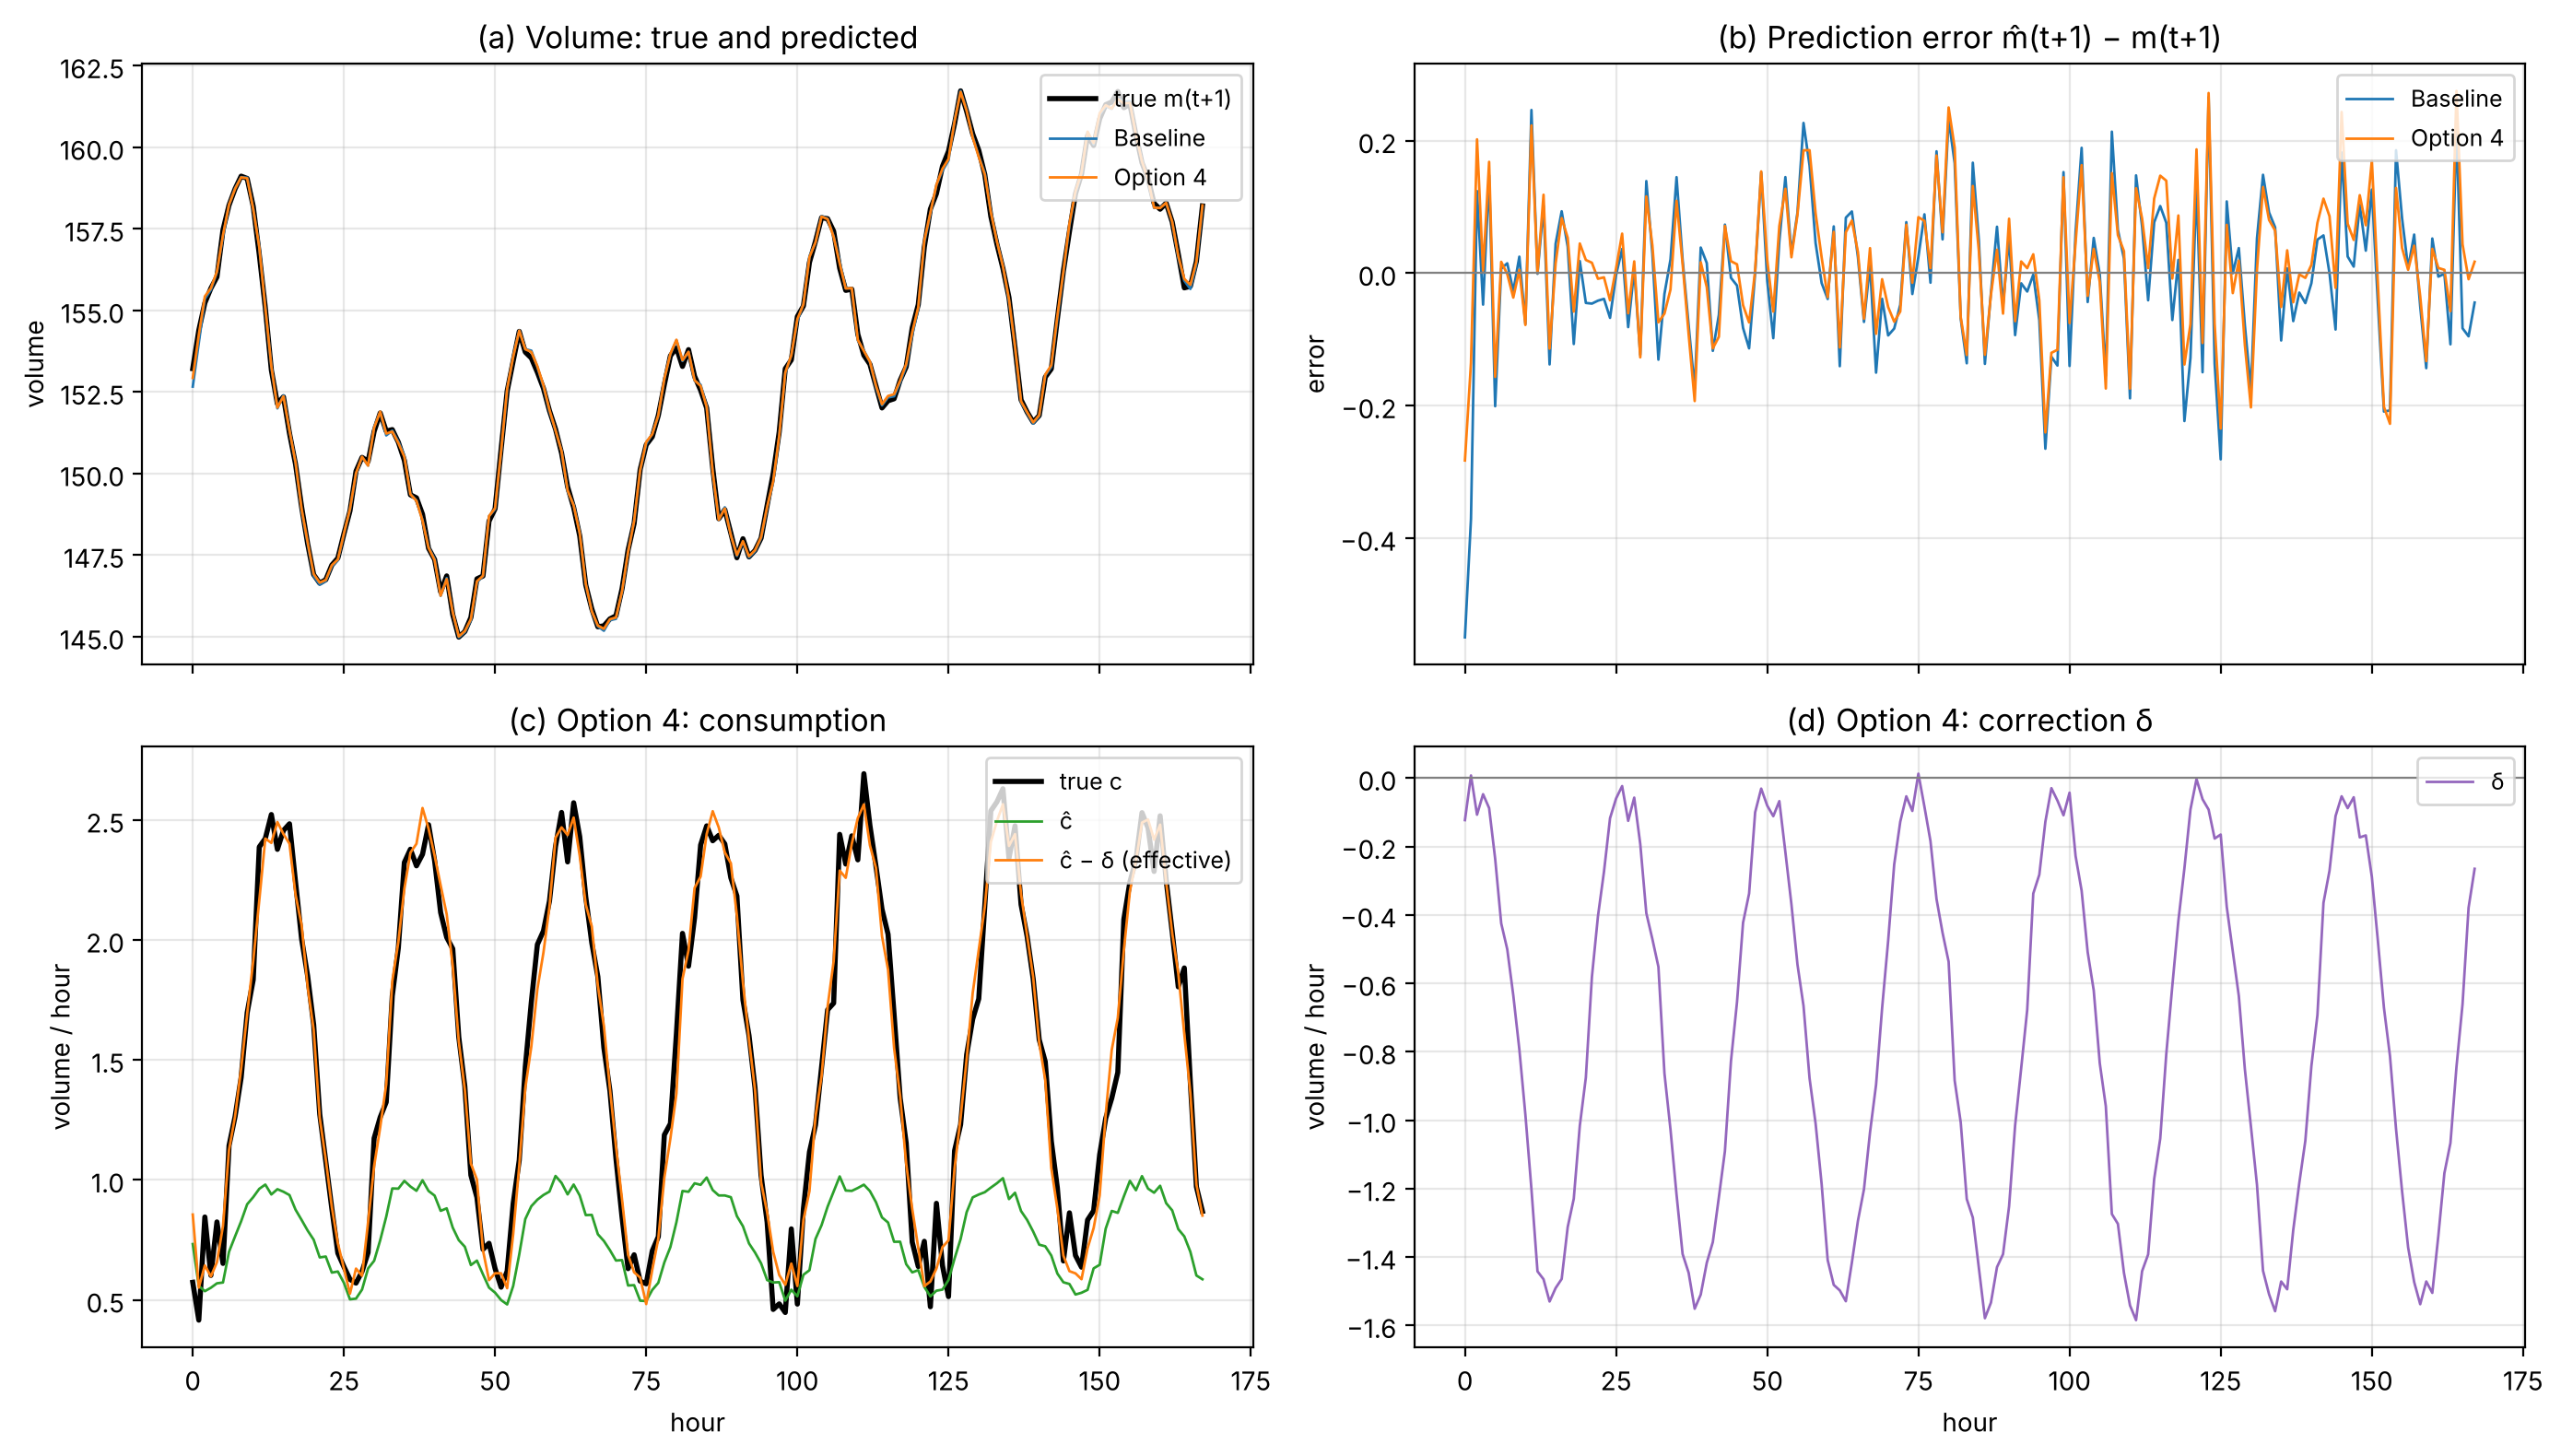

In [17]:
def plot_comparison(results, data, seq=0, hours=168):
    """Four-panel comparison of the two main runs on the first `hours` of test sequence `seq`.

    results : {"baseline": result, "opt4": result};  data : bundle of the test split
    Returns the figure.
    """
    t = np.arange(hours)
    y = np.asarray(data["Y_te"][seq, :hours])
    c_true = np.asarray(data["C_te"][seq, :hours])
    c_hat = results["opt4"]["test_c_hat"][seq, :hours]
    delta = results["opt4"]["test_delta"][seq, :hours]

    fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    (a, b), (c, d) = ax
    a.plot(t, y, color="black", lw=2, label="true m(t+1)")
    for label in ("baseline", "opt4"):
        pred = results[label]["test_m_pred"][seq, :hours]
        a.plot(t, pred, color=COLORS[label], lw=1, label=LABELS[label])
        b.plot(t, pred - y, color=COLORS[label], lw=1, label=LABELS[label])
    a.set(title="(a) Volume: true and predicted", ylabel="volume")
    b.axhline(0, color="grey", lw=0.8)
    b.set(title="(b) Prediction error m̂(t+1) − m(t+1)", ylabel="error")
    c.plot(t, c_true, color="black", lw=2, label="true c")
    c.plot(t, c_hat, color="tab:green", lw=1, label="ĉ")
    c.plot(t, c_hat - delta, color="tab:orange", lw=1, label="ĉ − δ (effective)")
    c.set(title="(c) Option 4: consumption", ylabel="volume / hour", xlabel="hour")
    d.plot(t, delta, color="tab:purple", lw=1, label="δ")
    d.axhline(0, color="grey", lw=0.8)
    d.set(title="(d) Option 4: correction δ", ylabel="volume / hour", xlabel="hour")
    for axis in ax.flat:
        axis.grid(alpha=0.3)
        axis.legend(fontsize=9, loc="upper right")
    plt.tight_layout()
    return fig


fig = plot_comparison(RESULTS, DATA)
plt.show()
assert len(fig.axes) == 4 and all(axis.get_title() and axis.get_legend() is not None for axis in fig.axes)

### The cold spell

The two main models, trained on normal temperatures, predict the cold-spell test set (`DATA_SHIFT`, 15 °C colder, normalized with the training statistics). No model is retrained. In the cold, consumption drops and is often exactly zero, so the true volume sits on the physical boundary `m(t+1) = m + r − q` much more often than in training. The table shows how much each model's MSE grows, and how often each breaks the balance there.

In [18]:
COLD = {label: evaluate(RESULTS[label], DATA_SHIFT, prefix="shift") for label in ("baseline", "opt4")}

print(f"Cold-spell test steps with c = 0: {float(np.mean(np.asarray(DATA_SHIFT['C_te']) == 0)):.1%}")
print(f"True volume, training set      : {float(DATA['Y_tr'].min()):.1f} – {float(DATA['Y_tr'].max()):.1f}")
print(f"True volume, cold-spell test   : {float(DATA_SHIFT['Y_te'].min()):.1f} – {float(DATA_SHIFT['Y_te'].max()):.1f}")
print(f"Cold-spell temperature (test)  : {float(DATA_SHIFT['X_te'][..., 3].min()):.1f} – "
      f"{float(DATA_SHIFT['X_te'][..., 3].max()):.1f} °C\n")

print(f"{'Model':10s}{'MSE in-dist':>13s}{'MSE cold':>12s}{'x worse':>10s}{'phys. cold':>12s}{'viol. cold':>12s}")
for label in ("baseline", "opt4"):
    e_in, e_c = EVAL[label], COLD[label]
    print(f"{LABELS[label]:10s}{e_in['mse']:>13.4g}{e_c['mse']:>12.4g}{e_c['mse'] / e_in['mse']:>10.3g}"
          f"{e_c['phys']:>12.3g}{e_c['share']:>12.2%}")

assert np.array_equal(DATA_SHIFT["x_mean"], DATA["x_mean"]) and DATA_SHIFT["y_mean"] == DATA["y_mean"]
assert all(np.isfinite(COLD[l][k]) for l in COLD for k in ("mse", "phys", "share"))

Cold-spell test steps with c = 0: 14.4%
True volume, training set      : 88.8 – 250.3
True volume, cold-spell test   : 149.5 – 568.4
Cold-spell temperature (test)  : -7.7 – 17.7 °C

Model       MSE in-dist    MSE cold   x worse  phys. cold  viol. cold
Baseline        0.01474   1.698e+04  1.15e+06    0.000158       0.15%
Option 4        0.01015      0.1648      16.2           0       0.00%


### Interpretation of section 8

- **Accuracy.** Option 4 has the lower test error: MSE 0.01015 against 0.01474 (1.45 times lower) and MAE 0.08037 against 0.09348. With 300 training sequences the gap is moderate; Option 4 is close to the noise floor of 0.01, so there is little room left below it.
- **Physical consistency.** The baseline implies negative consumption on 0.021 % of the test steps (physical error 5.15e-05): rare and small, but the balance is broken, as the assignment's expected pattern says. Option 4's physical error is 0 on this test set, which **differs from the expected pattern** ("generally nonzero"). The reason is in the diagnostics: `δ` is almost always negative (mean −0.7890), and a negative `δ` *increases* the implied consumption `ĉ − δ`, so it pushes away from the boundary instead of across it; and in the main data the true consumption never drops below 0.151, so the effective consumption, which tracks it with an MAE of 0.0804, has no reason to cross zero. This is a measurement on this set, not a guarantee: nothing in the architecture prevents `δ > ĉ`.
- **Cost.** Training took 103.3 s for the baseline and 96.9 s for Option 4 (on a 2-core CPU, compilation included). The second head and the balance cost nothing measurable: the difference is within the run-to-run variation of wall-clock time.
- **`ĉ` and `δ` are not identified.** Mean `│δ│` is 0.7903, 98 % of the mean `ĉ`, and `δ` follows the daily cycle (panel d). `ĉ` alone is far from the true consumption (MAE 0.7964), while `ĉ − δ` tracks it with an MAE of 0.0804, at the noise level (≈ 0.080). Under the plain MSE the model split the consumption between its two heads in an arbitrary way; only the difference is meaningful. `δ` is therefore *not* a measure of missing physics here, and 8E.1 tests whether a penalty fixes this.
- **Cold spell.** Out of distribution the difference is large: the baseline's MSE grows from 0.01474 to 1.698e+04 (about a million times worse) and it violates the balance on 0.15 % of steps; Option 4's grows from 0.01015 to 0.1648 (16.2 times) with no violation, although 14.4 % of the cold steps have `c = 0`. The cold inputs lie outside the training range (volumes up to 568.4 against at most 250.3 in training, temperatures from −7.7 °C), and the baseline must extrapolate the volume itself, while Option 4 gets `m + r − q` from the physics and only extrapolates the consumption.
- These are results for one seed and one kind of shift.

<a id='8E'></a>
## 8E. Extended experiments

Two claims of the Phase A plan are tested directly:

| Question | Experiment |
|---|---|
| Can `δ` be kept small, so that `ĉ` alone becomes the consumption, without losing accuracy? | **8E.1** — retrain Option 4 with a penalty `μ · mean(δ²)`, `μ` chosen on validation |
| Does the physics help more when data is scarce (physical knowledge as an inductive bias)? | **8E.2** — the low-data ablation: both models with 25–300 training sequences |

Every run uses the settings of section 7; only the factor of each experiment changes. `print_table` formats the tables of this section.

In [19]:
def print_table(rows, columns):
    """Print a table.

    rows    : list of (row label, dict of values)
    columns : list of (key, header, format string)
    """
    print(f"{'':12s}" + "".join(f"{h:>14s}" for _, h, _ in columns))
    for label, values in rows:
        print(f"{str(label):12s}" + "".join(f"{fmt.format(values[k]):>14s}" for k, _, fmt in columns))

### 8E.1 A penalty on δ

Under the plain MSE only `ĉ − δ` is determined (section 8). Adding `μ · mean(δ²)` to the loss gives the model a reason to prefer the smallest `δ` that fits the data, which makes the split identifiable: if the balance is complete, `δ → 0` and `ĉ` alone carries the consumption. Too large a `μ` could cost accuracy, so `μ` is chosen on **validation only**:

- candidates `μ ∈ {0, 0.01, 0.1, 1.0}` (`μ = 0` is the main run);
- among the candidates whose best validation MSE is within 2 % of the lowest, the **largest** `μ` is chosen (Option 4-R): the strongest penalty that does not measurably hurt accuracy.

The table then reports test metrics and the diagnostics of section 8 for every candidate; the true `c` is used only there, after the choice.

In [20]:
def select_mu(val_mse, tolerance=0.02):
    """Largest mu whose validation MSE is within `tolerance` (relative) of the lowest.

    val_mse : {mu: best validation MSE}
    Returns (chosen mu, threshold).
    """
    threshold = min(val_mse.values()) * (1 + tolerance)
    return max(mu for mu, v in val_mse.items() if v <= threshold), threshold


MU_RESULTS = {0.0: RESULTS["opt4"]}
for mu in CONFIG["mu_grid"]:
    MU_RESULTS[mu] = run_cached(f"opt4_mu{mu}_s{seed}", "option4", DATA, mu=mu)

val_mse = {mu: float(res["val_loss"].min()) for mu, res in MU_RESULTS.items()}
MU_CHOSEN, threshold = select_mu(val_mse)

rows = []
for mu, res in MU_RESULTS.items():
    e = evaluate(res, DATA)
    rows.append((f"μ = {mu:g}", {"val": val_mse[mu], **e}))
print()
print_table(rows, [("val", "val MSE", "{:.4g}"), ("mse", "test MSE", "{:.4g}"), ("phys", "phys. error", "{:.3g}"),
                   ("share", "viol. share", "{:.3%}"), ("mean_abs_delta", "mean |δ|", "{:.4f}"),
                   ("mean_delta", "mean δ", "{:+.4f}"), ("mae_c", "MAE ĉ", "{:.4f}"),
                   ("mae_eff", "MAE ĉ − δ", "{:.4f}")])
print(f"\nRule: largest μ with validation MSE ≤ {threshold:.4g} (lowest + 2 %) → chosen μ = {MU_CHOSEN:g}")

assert len(MU_RESULTS) == 4
assert (MU_CHOSEN, threshold) == select_mu({mu: float(r["val_loss"].min()) for mu, r in MU_RESULTS.items()})
assert val_mse[MU_CHOSEN] <= threshold

opt4_mu0.01_s112358: computed


opt4_mu0.1_s112358: computed


opt4_mu1.0_s112358: computed

                   val MSE      test MSE   phys. error   viol. share      mean |δ|        mean δ         MAE ĉ     MAE ĉ − δ
μ = 0             0.009917       0.01015             0        0.000%        0.7903       -0.7890        0.7964        0.0804
μ = 0.01          0.009942       0.01015             0        0.000%        0.0217       -0.0031        0.0844        0.0804
μ = 0.1           0.009919       0.01015             0        0.000%        0.0059       -0.0010        0.0808        0.0804
μ = 1             0.009906       0.01013             0        0.000%        0.0018       +0.0004        0.0803        0.0803

Rule: largest μ with validation MSE ≤ 0.0101 (lowest + 2 %) → chosen μ = 1


The consumption head `ĉ` against the true `c` on the first week of test sequence 0, without the penalty (`μ = 0`) and with the chosen `μ`. If the penalty works, `ĉ` itself should follow the true consumption.

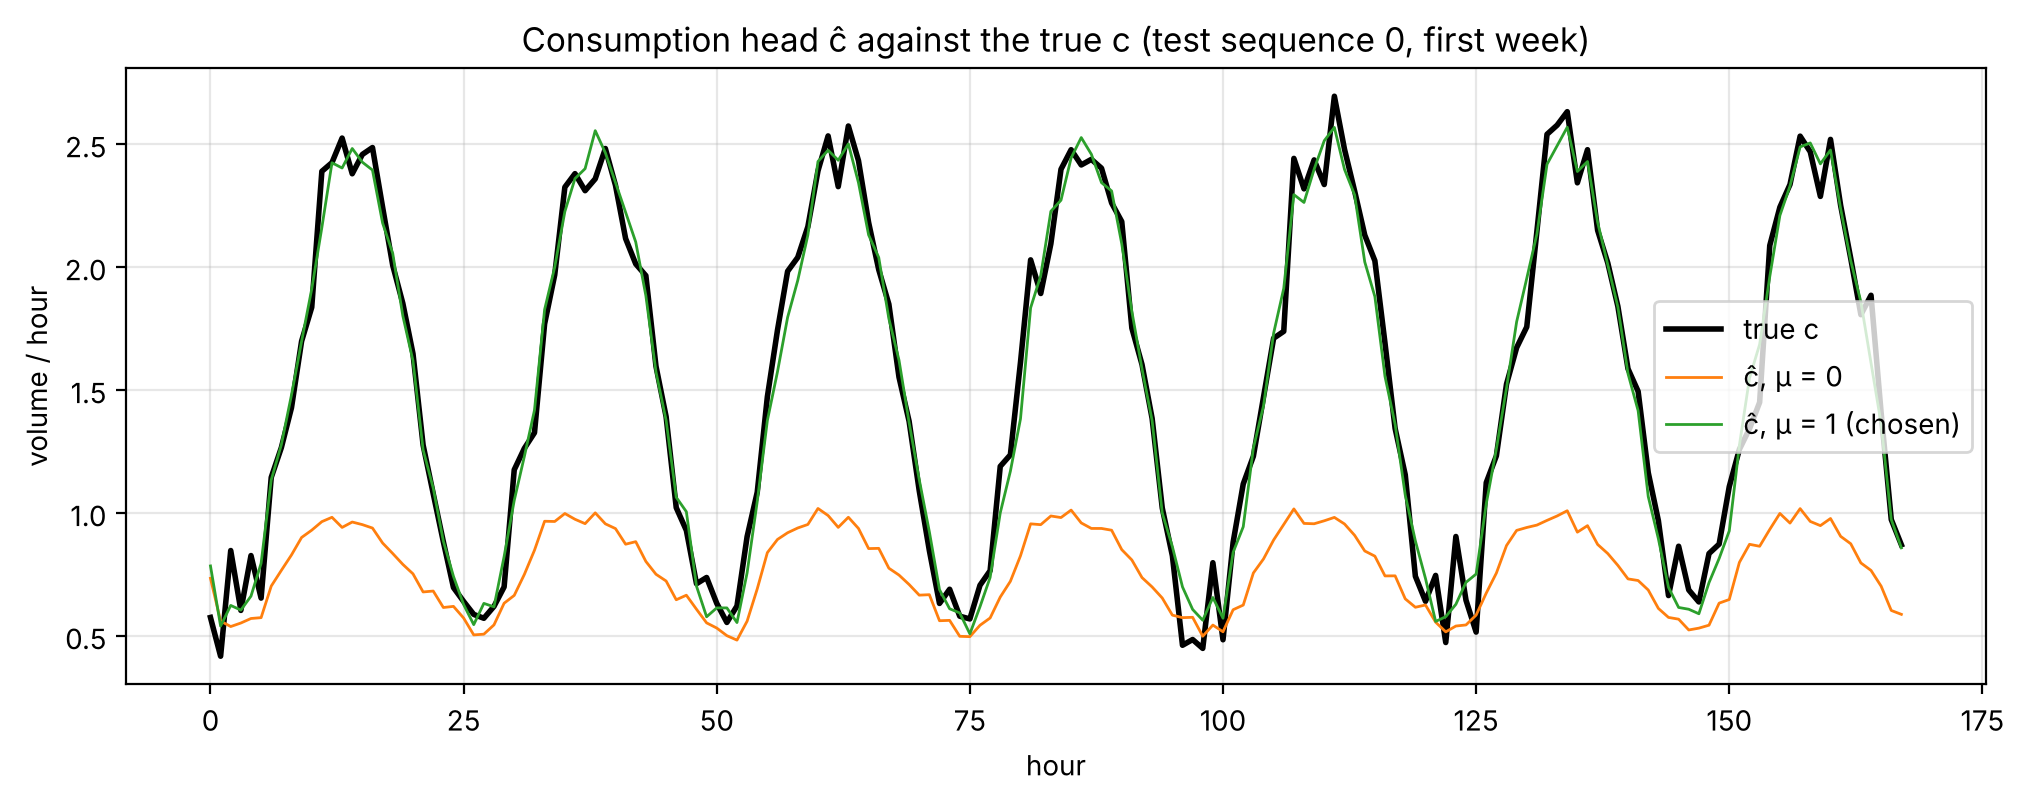

In [21]:
hours = 168
t = np.arange(hours)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t, np.asarray(DATA["C_te"][0, :hours]), color="black", lw=2, label="true c")
for mu, color in ((0.0, "tab:orange"), (MU_CHOSEN, "tab:green")):
    if mu == 0.0 and MU_CHOSEN == 0.0:
        continue
    ax.plot(t, MU_RESULTS[mu]["test_c_hat"][0, :hours], color=color, lw=1,
            label=f"ĉ, μ = {mu:g}" + (" (chosen)" if mu == MU_CHOSEN else ""))
if MU_CHOSEN == 0.0:
    ax.plot(t, MU_RESULTS[0.0]["test_c_hat"][0, :hours], color="tab:orange", lw=1, label="ĉ, μ = 0 (chosen)")
ax.set(title="Consumption head ĉ against the true c (test sequence 0, first week)",
       xlabel="hour", ylabel="volume / hour")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### Interpretation of 8E.1

- **The penalty removes the ambiguity.** Even the smallest penalty shrinks mean `│δ│` from 0.7903 to 0.0217 (`μ = 0.01`); with `μ = 1` it is 0.0018. The MAE of `ĉ` alone then drops from 0.7964 to 0.0803, equal to the MAE of `ĉ − δ`: the consumption head becomes the recovered consumption, as the plot shows.
- **No cost in accuracy.** The validation MSE stays between 0.009906 and 0.009942 for all four values and the test MSE between 0.01013 and 0.01015. The rule chose `μ = 1` (the largest candidate within 2 % of the lowest validation MSE, threshold 0.0101); `μ = 1` also happened to have the lowest validation MSE, so no trade-off appeared in this range. Larger values were not tested.
- **Physical consistency** is unchanged: physical error 0 and no violations for every `μ`.
- **What it means for the Phase A plan.** With `δ` penalized, a `δ` that stays near zero is evidence that the balance is complete for this data — which it is by construction. The plain Option 4 could not give that evidence, because its `δ` was large for no physical reason. If the balance were incomplete, the penalty would let `δ` grow only where the data required it.

### 8E.2 Low-data ablation

The assignment's recommended bonus. Both models are retrained with only the first `n_train ∈ {25, 50, 100, 200}` training sequences (300 is the main run). Validation and test sets and all settings stay fixed; normalization statistics come from the sequences actually used. If the conservation law is a useful inductive bias, Option 4 should lose less accuracy than the baseline as data shrinks, because it only has to learn the small consumption term while the baseline must learn the whole mapping to the volume. Eight new runs; no cold-spell predictions.

In [22]:
N_SIZES = CONFIG["n_train_grid"] + [CONFIG["n_train"]]
LOW_DATA = {n: make_dataset(data_key, n_train=n, tag=f"n{n}") for n in CONFIG["n_train_grid"]}
LOW_DATA[CONFIG["n_train"]] = DATA
LOW_RESULTS = {"baseline": {}, "opt4": {}}
for n in CONFIG["n_train_grid"]:
    for label, kind in (("baseline", "baseline"), ("opt4", "option4")):
        LOW_RESULTS[label][n] = run_cached(f"{label}_n{n}_s{seed}", kind, LOW_DATA[n])
for label in LOW_RESULTS:
    LOW_RESULTS[label][CONFIG["n_train"]] = RESULTS[label]

LOW_EVAL = {label: {n: evaluate(LOW_RESULTS[label][n], LOW_DATA[n]) for n in N_SIZES} for label in LOW_RESULTS}
rows = [(f"n = {n}", {"mse_b": LOW_EVAL["baseline"][n]["mse"], "mse_o": LOW_EVAL["opt4"][n]["mse"],
                      "ratio": LOW_EVAL["baseline"][n]["mse"] / LOW_EVAL["opt4"][n]["mse"],
                      "viol_b": LOW_EVAL["baseline"][n]["share"], "viol_o": LOW_EVAL["opt4"][n]["share"],
                      "phys_b": LOW_EVAL["baseline"][n]["phys"], "phys_o": LOW_EVAL["opt4"][n]["phys"]})
        for n in N_SIZES]
print()
print_table(rows, [("mse_b", "MSE base", "{:.4g}"), ("mse_o", "MSE opt4", "{:.4g}"),
                   ("ratio", "base / opt4", "{:.1f}"), ("viol_b", "viol. base", "{:.3%}"),
                   ("viol_o", "viol. opt4", "{:.3%}"), ("phys_b", "phys. base", "{:.3g}"),
                   ("phys_o", "phys. opt4", "{:.3g}")])

assert all(len(LOW_EVAL[label]) == 5 for label in LOW_EVAL)
for n in N_SIZES:
    for k in ("X_va", "Y_va", "X_te", "Y_te"):
        assert bool(jnp.array_equal(LOW_DATA[n][k], DATA[k]))

baseline_n25_s112358: computed


opt4_n25_s112358: computed


baseline_n50_s112358: computed


opt4_n50_s112358: computed


baseline_n100_s112358: computed


opt4_n100_s112358: computed


baseline_n200_s112358: computed


opt4_n200_s112358: computed

                  MSE base      MSE opt4   base / opt4    viol. base    viol. opt4    phys. base    phys. opt4
n = 25               6.276       0.01379         454.9        6.177%        0.000%         0.333             0
n = 50              0.2311       0.01108          20.9        0.500%        0.000%        0.0162             0
n = 100              0.038        0.0104           3.7        0.112%        0.000%       0.00234             0
n = 200            0.02162       0.01025           2.1        0.023%        0.000%      0.000101             0
n = 300            0.01474       0.01015           1.5        0.021%        0.000%      5.15e-05             0


Test MSE against the number of training sequences (log–log; the dotted line is the variance of the consumption noise, 0.01, which no model can predict), and the share of test steps where each model breaks the balance.

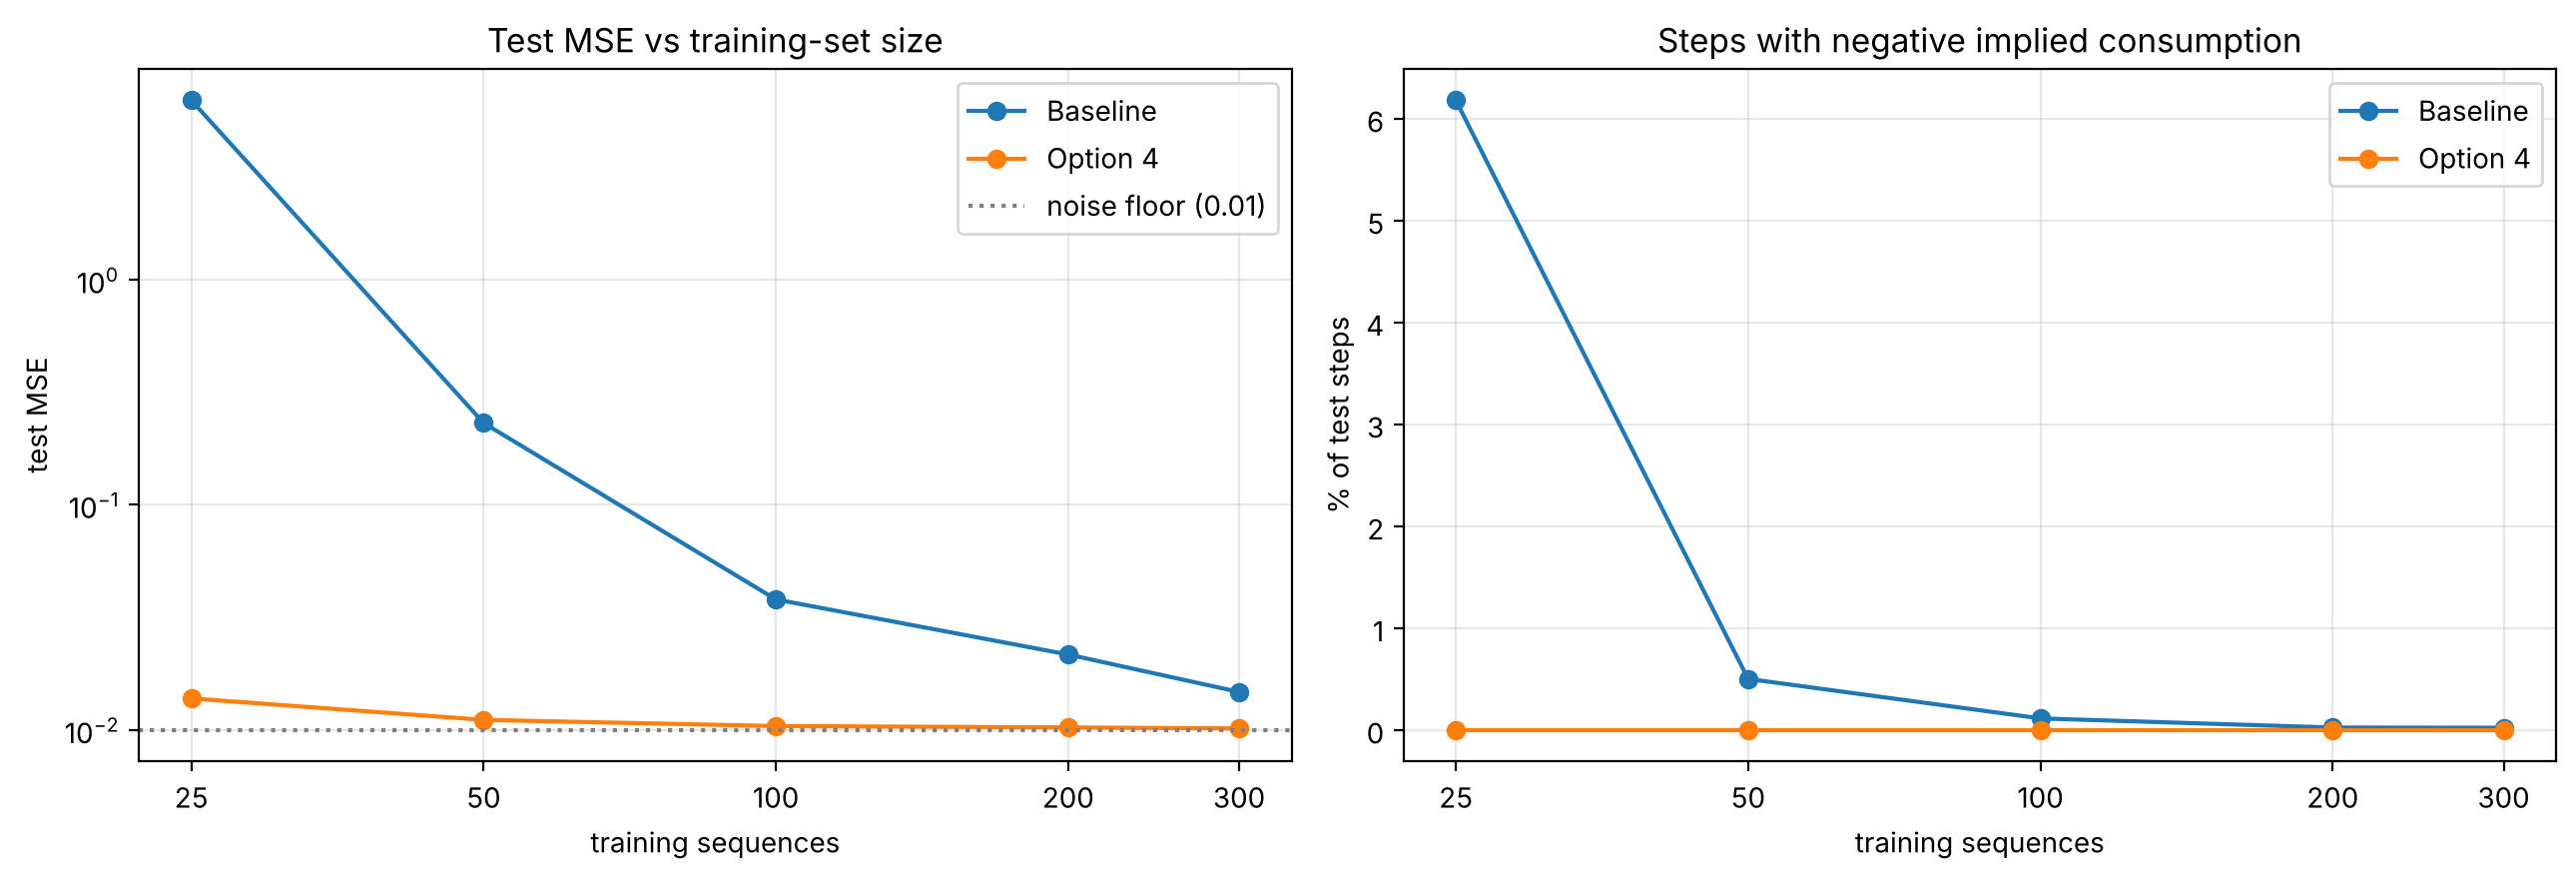

In [23]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.5))
for label in ("baseline", "opt4"):
    a.plot(N_SIZES, [LOW_EVAL[label][n]["mse"] for n in N_SIZES], "o-", color=COLORS[label], label=LABELS[label])
    b.plot(N_SIZES, [100 * LOW_EVAL[label][n]["share"] for n in N_SIZES], "o-", color=COLORS[label],
           label=LABELS[label])
a.axhline(0.01, color="grey", ls=":", label="noise floor (0.01)")
a.set(xscale="log", yscale="log", title="Test MSE vs training-set size",
      xlabel="training sequences", ylabel="test MSE")
b.set(xscale="log", title="Steps with negative implied consumption",
      xlabel="training sequences", ylabel="% of test steps")
for axis in (a, b):
    axis.set_xticks(N_SIZES)
    axis.set_xticklabels([str(n) for n in N_SIZES])
    axis.minorticks_off()
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

### Interpretation of 8E.2

- **Accuracy.** Option 4 barely changes with the data: test MSE 0.01379 with 25 sequences and 0.01015 with 300, always close to the noise floor of 0.01. The baseline's MSE goes from 6.276 with 25 sequences to 0.01474 with 300. The ratio baseline / Option 4 is 454.9 at 25, 20.9 at 50, 3.7 at 100, 2.1 at 200 and 1.5 at 300: the less data, the more the physics helps.
- **Physical consistency.** With 25 sequences the baseline implies negative consumption on 6.177 % of the test steps (physical error 0.333); the share falls to 0.500 % at 50 and 0.021 % at 300 but never to zero. Option 4 has no violation at any size.
- **Why.** Option 4 receives `m + r − q` from the balance and only learns a consumption of order 1 from temperature and time, a much smaller function to learn. The baseline must learn the mapping from the whole input to a volume of order 150, including the balance itself, and that needs data. This is the inductive bias of the Phase A plan, measured.
- One seed: the small-data points, especially the baseline's at 25 sequences, would vary with another seed; the size of the gap, two orders of magnitude, would not be explained by that.

<a id='10'></a>
## 9. Reflection questions

Answer using evidence from **your own** experiments — refer to your metrics table and plots, not just general reasoning.

**1. Why can a conventional LSTM violate a physical law, even after being trained to convergence on plenty of data?**

_Notes (for the answer below):_

- MSE scores only the distance to the target: a prediction 0.4 above the boundary `m + r − q` and one 0.4 below the truth get the same loss, so nothing pushes the model to the physical side (Phase A, Discussion 2).
- The law is in neither the architecture nor the loss; the baseline can only approximate it from data, and an approximation has errors on both sides.
- Evidence — section 8 table: trained to its best validation epoch (273) on 300 sequences, the baseline still implies negative consumption on 0.021 % of test steps (physical error 5.15e-05).
- 8E.2: the violations shrink with data (6.177 % at 25 sequences, 0.500 % at 50, 0.021 % at 300) but do not vanish: more data reduces them, nothing removes them.
- Cold spell (section 8): outside the training range violations rise to 0.15 % and the MSE to 1.698e+04 — convergence on training data says nothing about inputs not seen.
- The risk is largest where the true `c` is near zero, because the truth then lies close to the boundary.

_Your answer:_

*(write here)*

**2. What is the difference between a soft constraint and a hard constraint? If you implemented Option 3 or 4, where would a soft constraint have gone instead, and how would training/evaluation have differed? If you implemented Option 2, reflect on how your choice of `λ` affected the accuracy/conservation trade-off.**

_Notes (for the answer below):_

- Soft constraint: the law is a penalty in the loss, traded against accuracy through `λ`; violations become less likely but stay possible, also on new data. Hard constraint: the law is in the architecture, so it holds for any parameters, before training and out of distribution.
- Option 4 sits between: the balance is hard-wired, `ĉ ≥ 0` by softplus, but `δ` is free, so conservation is approximate. Measured: physical error 0 for Option 4 on the test set and on the cold spell (section 8), but not guaranteed.
- Where a soft constraint would have gone: a second output `m̂` next to `ĉ`, and a loss term `λ · (m̂ − m − r + q + ĉ)²` (Option 2). Training would need a `λ` search (several runs, chosen on validation), and evaluation would have to measure the remaining violation for each `λ`.
- 8E.1 is itself a soft constraint, on `δ`: `μ · mean(δ²)` shrinks mean `│δ│` from 0.7903 to 0.0018 (`μ = 1`) with no loss of accuracy (test MSE 0.01015 → 0.01013) — but `δ` is still not zero by construction.
- Cost of the hard structure: none measurable — 96.9 s for Option 4 vs 103.3 s for the baseline (section 8 table), 33 extra parameters.

_Your answer:_

*(write here)*

**3. How does physical knowledge act as an inductive bias? Explain how you would test this claim with the optional low-data ablation described in the assignment, and connect it to your own results if you ran it.**

_Notes (for the answer below):_

- Inductive bias = what the model assumes before seeing data. Option 4 assumes the balance: the network only has to learn the consumption (order 1), not the volume (order 150).
- Section 7: Option 4's first-epoch training loss is 0.5097 against 213 for the baseline — it starts near the answer.
- Test with the low-data ablation (8E.2): retrain both with fewer sequences, everything else fixed, and compare test MSE vs `n_train`. Claim supported if Option 4 degrades less.
- 8E.2 results: Option 4 test MSE 0.01379 (25 seq.) → 0.01015 (300), near the 0.01 noise floor at every size; baseline 6.276 → 0.01474; ratio 454.9 at 25 down to 1.5 at 300.
- Violations (8E.2): baseline 6.177 % of steps at 25 sequences, Option 4 0 % at every size.
- Also a generalization effect: on the cold spell Option 4 is 16.2 times worse than in distribution, the baseline about a million times (section 8).
- Limits: one seed, simulated data that obeys the law exactly (the bias is correct by construction).

_Your answer:_

*(write here)*

**4. In what other application domains could this idea (predicting an unknown residual term and reconstructing the target analytically) be useful? Give at least one concrete example outside of hydrology.**

_Notes (for the answer below):_

- Pattern: a known balance with one unknown term → learn the term, compute the target from the balance.
- Battery state of charge: `SoC(t+1) = SoC(t) + η·I(t)·Δt/Q − losses`; current is measured, the network learns losses/self-discharge (≥ 0) from temperature and age.
- Building energy: indoor heat balance with measured heating power; the network learns unmetered gains/losses (occupants, solar, infiltration).
- Epidemiology: compartment models (S + I + R = N conserved); the network learns the time-varying transmission rate, the compartments follow from the equations.
- Inventory / supply chain: `stock(t+1) = stock + deliveries − recorded sales − shrinkage`; shrinkage (theft, spoilage, ≥ 0) is the hidden term.
- Chemical reactors / process engineering: species mass balances with a learned reaction rate.
- Also: traffic (vehicles conserved on a road segment), accounting (a ledger must balance).

_Your answer:_

*(write here)*

**5. How could causality, rather than mass conservation, be incorporated into a neural network architecture? What would "hard enforcement" of a causal constraint even mean, compared to enforcing a conservation law?**

_Notes (for the answer below):_

- Temporal causality ("the output at t depends only on inputs up to t") can be hard-wired: the forward-only LSTM of this notebook already does it — `m̂(t+1)` is computed from `x(0..t)` only; causal convolutions and masked attention do the same.
- Causal structure between variables (a known graph): restrict which inputs reach which outputs (masked weights, separate sub-networks per mechanism), so that a non-cause has exactly zero influence; or encode known signs and monotonicity (e.g. consumption increasing with temperature) by construction.
- Hard enforcement here would mean: the dependence is impossible for any parameters (zero gradient path), like `ĉ ≥ 0` by softplus — not merely penalized.
- Difference from conservation: a conservation law is an equation checkable at every step from observed data (our physical error). A causal claim is about interventions / counterfactuals and cannot be verified from observational data alone; and the graph itself must be assumed, so a wrong graph is enforced just as strictly.
- Soft versions: penalties for dependence on non-causes, invariance across environments (e.g. train so predictions stay stable under the cold-spell shift).

_Your answer:_

*(write here)*

<a id='11'></a>
## 11. Before you submit

**Common pitfalls to double-check:**
- The true `c(t)` never leaks into either model's inputs.
- Train/test split is by *sequence*, not by timestep.
- Normalization statistics come from the training split only.
- Your model's mass computation (Options 3/4) or physics loss term (Option 2) uses raw, unnormalized `m, r, q`.
- Both models used the same hidden size, optimizer, learning rate, epochs, and batch size.
- You didn't reuse a JAX PRNG key without splitting it first.

### Final checks

The pitfalls above, checked in code over every run of this notebook (all are read back from `results/`).

In [24]:
BUNDLES = {"main": DATA, "shift": DATA_SHIFT, **{f"n{n}": LOW_DATA[n] for n in CONFIG["n_train_grid"]}}
STORED = {}
for name in RUNS:
    with np.load(os.path.join("results", f"{name}.npz")) as f:
        STORED[name] = {k: f[k] for k in f.files}

# 1. c(t) never enters the models
batch = make_batch(DATA["Xn_tr"], {"x": DATA["X_tr"]}, DATA["Y_tr"], jnp.arange(BATCH_SIZE))
assert all(b[f"X{s}_{p}"].shape[-1] == 6 for b in BUNDLES.values() for s in ("", "n") for p in ("tr", "va", "te"))
assert set(batch) == {"xn", "x", "y"}
print("✓ 1. c(t) never enters the models: 6 input features, batches hold only xn, x, y")

# 2. No sequence in two splits (a sequence is identified by its first 5 volumes)
def signatures(X_split):
    return {tuple(np.asarray(s[:5, 0]).tolist()) for s in X_split}
for b in BUNDLES.values():
    tr, va, te = signatures(b["X_tr"]), signatures(b["X_va"]), signatures(b["X_te"])
    assert not (tr & va or tr & te or va & te)
    assert len(tr) == b["X_tr"].shape[0] and len(te) == b["X_te"].shape[0]
print("✓ 2. Train, validation and test share no sequence")

# 3. Normalization statistics from the training split
for name, b in BUNDLES.items():
    if name == "shift":
        assert np.array_equal(b["x_mean"], DATA["x_mean"]) and b["y_std"] == DATA["y_std"]
    else:
        x64 = np.asarray(b["X_tr"], np.float64)
        assert np.allclose(b["x_mean"], x64.mean(axis=(0, 1)), rtol=1e-6)
        assert np.allclose(b["x_std"], x64.std(axis=(0, 1)), rtol=1e-6)
        assert np.isclose(b["y_mean"], np.asarray(b["Y_tr"], np.float64).mean())
print("✓ 3. Normalization statistics come from the training split")

# 4. Identical settings
expected_params = {"baseline": 5025, "option4": 5058}
mu_runs = {f"opt4_mu{mu}_s{seed}" for mu in CONFIG["mu_grid"]}
for name, s in STORED.items():
    assert len(s["train_loss"]) == len(s["val_loss"]) == EPOCHS
    assert int(s["n_params"]) == expected_params[str(s["kind"])] and str(s["kind"]) == RUNS[name]["kind"]
    assert (float(s["mu"]) > 0) == (name in mu_runs)
print(f"✓ 4. All {len(STORED)} runs used the same settings ({EPOCHS} epochs; μ > 0 only in 8E.1)")

# 5. Raw units in Option 4's balance
s, Xt = STORED[f"opt4_s{seed}"], np.asarray(DATA["X_te"])
balance = ((Xt[..., 0] + Xt[..., 1]) - Xt[..., 2]) - s["test_c_hat"] + s["test_delta"]
assert np.max(np.abs(s["test_m_pred"] - balance)) < 1e-3
print("✓ 5. Option 4's balance uses raw physical units")

# 6. A different PRNG key for every run
keys = {tuple(np.asarray(run_key(name, RUNS[name]["seed"])).ravel().tolist()) for name in RUNS}
assert len(keys) == len(RUNS)
print("✓ 6. Every run has its own random key")
print("All 6 checks passed.")

✓ 1. c(t) never enters the models: 6 input features, batches hold only xn, x, y


✓ 2. Train, validation and test share no sequence
✓ 3. Normalization statistics come from the training split
✓ 4. All 13 runs used the same settings (300 epochs; μ > 0 only in 8E.1)
✓ 5. Option 4's balance uses raw physical units
✓ 6. Every run has its own random key
All 6 checks passed.


**Deliverables checklist:**
- [x] Reproducible notebook, seeded end-to-end with explicit `PRNGKey`s
- [x] Synthetic data generator with a sanity-check plot of at least one simulated sequence
- [x] Baseline LSTM implementation (Option 1)
- [x] Your chosen model implementation (Option 2, 3, or 4 -- matching your Phase A plan)
- [x] Both models trained under identical settings, with training-loss curves plotted together
- [x] Metrics table (MSE, MAE, physical error, training time) on the test set for both models
- [x] *(recommended, optional bonus)* Low-data ablation plot (test MSE vs. training-set size)
- [ ] Written answers to all five reflection questions, grounded in your own results